# Práctica 2 (parte 1): Red Convolucional Personalizada (EuroSAT)
## Aprendizaje Profundo - Grado en Inteligencia Artificial
**Universidade da Coruña (UDC)**

---

### Información del Grupo de Prácticas
* **Autores:** Xoel Sánchez Dacoba y Sebastián David Moreno Expósito
* **Código del Grupo de Prácticas:** [Ej. Grupo_XX]
* **Fecha:** Noviembre 2026
* **Dataset:** EuroSAT RGB (Sentinel-2, 10 clases de uso de suelo)
* **Cuadernos de la P2:** `P2_1_EuroSAT_CNN_personalizada.ipynb` (este) y `P2_2_EuroSAT_CNN_preentrenadas.ipynb`

---

## Índice de Contenidos
1. **[Configuración del Entorno y Reproducibilidad](#sec1)**
2. **[Carga y Exploración del Dataset EuroSAT](#sec2)**
3. **[Preprocesado del Dataset](#sec3)** (misma partición que en la P1, pero **sin aplanar** la imagen)
4. **[Metodología Experimental y Funciones de Apoyo](#sec4)**
5. **[Modelo 1: CNN Base (sin regularización)](#sec5)**
6. **[Búsqueda de la Arquitectura (capas, filtros, kernels, cabeza)](#sec6)**
7. **[Experimentación con Medidas de Regularización](#sec7)**
   * 7.1. *Modelo 2: Arquitectura elegida sin regularización (referencia)*
   * 7.2. *Modelo 3: Aumento de datos (Data Augmentation)*
   * 7.3. *Modelo 4: Dropout*
   * 7.4. *Modelo 5: Batch Normalization*
   * 7.5. *Modelo 6: Regularización $L_2$*
8. **[Optimización y Modelo Final](#sec8)**
   * 8.1. *Modelo 7: Combinación final con Adam + ReduceLROnPlateau + Early Stopping*
   * 8.2. *Modelo 8: Misma red con SGD + momento de Nesterov*
   * 8.3. *Diagnóstico y corrección: Modelos 9 y 10 (entrenamiento largo con decaimiento coseno)*
9. **[Comparación Global de Resultados (incluida la P1)](#sec9)**
10. **[Conclusiones](#sec10)**

<a id="sec1"></a>
## 1. Configuración del Entorno y Reproducibilidad

Usamos las mismas librerías que en la P1 (tensorflow, keras, tensorflow_datasets, numpy, matplotlib, pandas, sklearn) y la misma semilla (`SEED = 255256`).

Una diferencia respecto a la P1: aquí la semilla se vuelve a fijar **antes de crear cada modelo** (función `reset_seed`). Así cada experimento empieza desde la misma inicialización aunque se ejecuten las celdas en otro orden, y las diferencias entre modelos se deben a su diseño y no al azar de la inicialización.

> Nota: en GPU algunas operaciones de cuDNN no son deterministas, por lo que al repetir una ejecución pueden aparecer diferencias de unas décimas en la exactitud. Las conclusiones no dependen de esas décimas.

In [1]:
import os
import json
import time
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")  # menos mensajes internos de TensorFlow en la salida
import tensorflow as tf
import keras
from keras import layers, regularizers, callbacks
import tensorflow_datasets as tfds
from sklearn.metrics import classification_report, confusion_matrix
import warnings
warnings.filterwarnings("ignore", message=".*shuffle=True.*")  # aviso inofensivo de Keras con tf.data

SEED = 255256  # misma semilla que en la P1

def reset_seed(seed=SEED):
    """Fija las semillas de Python, NumPy y TensorFlow (se llama antes de crear cada modelo)."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    keras.utils.set_random_seed(seed)

reset_seed()

print(f"TensorFlow v: {tf.__version__} | Keras v: {keras.__version__}")
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    tf.config.set_visible_devices(gpus[0], "GPU")          # si hay varias GPU, usamos solo la primera
    tf.config.experimental.set_memory_growth(gpus[0], True)  # reserva memoria de la GPU según se necesita
    print("GPU usada:", tf.config.experimental.get_device_details(gpus[0]).get("device_name"))
else:
    print("No se detectó GPU: el entrenamiento irá en CPU (mucho más lento)")

RESULTS_DIR = "resultados"  # aquí se guardan los resultados para el cuaderno 2 (comparación final)
os.makedirs(RESULTS_DIR, exist_ok=True)

I0000 00:00:1794933983.137541     511 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794933984.767272     511 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow v: 2.21.0 | Keras v: 3.15.1
GPU usada: NVIDIA GeForce RTX 5060 Ti


<a id="sec2"></a>
## 2. Carga y Exploración del Dataset EuroSAT

Es el mismo dataset de la P1: 27.000 imágenes RGB de $64 \times 64$ píxeles del satélite Sentinel-2, repartidas en 10 clases de uso del suelo.

**Problema encontrado con la descarga:** `tensorflow_datasets` descarga EuroSAT desde el servidor original (`madm.dfki.de`), que ha dejado de responder (la descarga se queda colgada). Por eso la función `preparar_eurosat` le indica a `tensorflow_datasets` que descargue la **copia oficial de Zenodo** (la que cita el enunciado) y prepare el dataset igual que siempre.

Esto **no cambia la partición**: `tensorflow_datasets` ordena los ejemplos según el nombre de cada fichero (por ejemplo `Forest_864.jpg`), y los nombres son los mismos en las dos copias. En la sección 3 lo comprobamos: el conjunto de test tiene exactamente los mismos recuentos por clase que el de la P1.

In [2]:
def preparar_eurosat():
    """Prepara EuroSAT RGB en tensorflow_datasets descargándolo de Zenodo (solo la primera vez)."""
    builder = tfds.builder("eurosat/rgb")
    if tf.io.gfile.exists(os.path.join(builder.data_dir, "dataset_info.json")):
        print("EuroSAT ya está preparado en", builder.data_dir)
        return
    builder.builder_config.download_url = "https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip"
    builder.builder_config.subdir = "EuroSAT_RGB"  # carpeta interna del ZIP de Zenodo
    builder.download_and_prepare()

preparar_eurosat()

raw_ds, ds_info = tfds.load("eurosat/rgb", with_info=True, as_supervised=True)
class_names = ds_info.features["label"].names
num_classes = ds_info.features["label"].num_classes
print(f"Total de ejemplos: {ds_info.splits['train'].num_examples}")
print(f"Número de clases: {num_classes}")
for idx, name in enumerate(class_names):
    print(f"  [{idx}] {name}")

EuroSAT ya está preparado en /home/sebastian/tensorflow_datasets/eurosat/rgb/2.0.0


Total de ejemplos: 27000
Número de clases: 10
  [0] AnnualCrop
  [1] Forest
  [2] HerbaceousVegetation
  [3] Highway
  [4] Industrial
  [5] Pasture
  [6] PermanentCrop
  [7] Residential
  [8] River
  [9] SeaLake


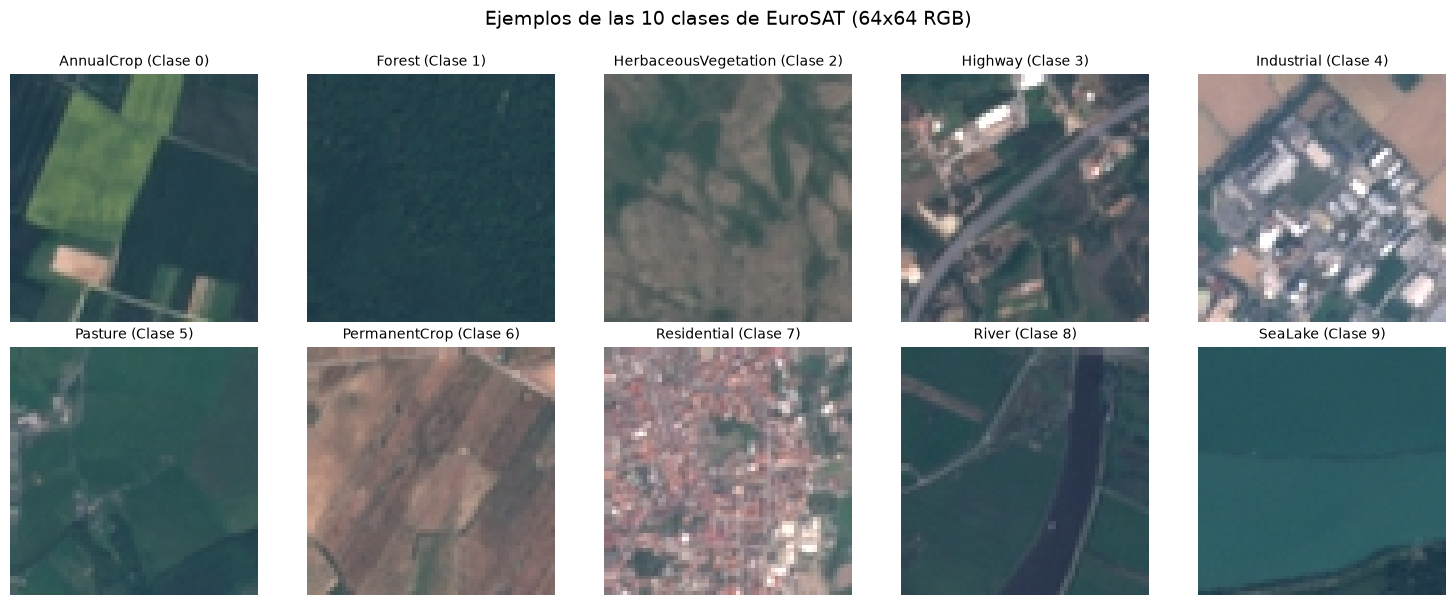

In [3]:
samples_per_class = {}  # una imagen de cada clase, solo para visualizar
for img, label in raw_ds["train"]:
    lbl = int(label.numpy())
    if lbl not in samples_per_class:
        samples_per_class[lbl] = img.numpy()
    if len(samples_per_class) == num_classes:
        break

plt.figure(figsize=(15, 6))
for i in range(num_classes):
    plt.subplot(2, 5, i + 1)
    plt.imshow(samples_per_class[i])
    plt.title(f"{class_names[i]} (Clase {i})", fontsize=10)
    plt.axis("off")
plt.suptitle("Ejemplos de las 10 clases de EuroSAT (64x64 RGB)", fontsize=14, y=1)
plt.tight_layout()
plt.show()

<a id="sec3"></a>
## 3. Preprocesado del Dataset

El preprocesado es el de la P1 con **un único cambio**, el que pide el enunciado:

1. **Partición 70% / 15% / 15%** (entrenamiento 18.900, validación 4.050, test 4.050): la misma de la P1, para que los resultados se puedan comparar directamente.
2. **Normalización a $[0, 1]$** dividiendo entre 255.
3. **Codificación one-hot** de las etiquetas (vector de 10 posiciones), para la pérdida `categorical_crossentropy`.
4. **Ya no se aplana la imagen.** En la P1 cada imagen se convertía en un vector de $64 \cdot 64 \cdot 3 = 12.288$ números, y la red densa perdía qué píxeles son vecinos. Una capa convolucional recibe la imagen como un **mapa bidimensional** de forma $(alto, ancho, canales) = (64, 64, 3)$ y recorre con sus filtros zonas de píxeles vecinos, así que la estructura espacial se conserva.

Además creamos `train_eval_ds`: el conjunto de entrenamiento **sin barajar**, que solo se usa para medir la exactitud en entrenamiento con los pesos finales (sin dropout ni aumento de datos activos), de modo que la brecha entrenamiento-validación se mida en igualdad de condiciones.

In [4]:
(raw_train, raw_val, raw_test) = tfds.load(
    "eurosat/rgb",
    split=["train[:70%]", "train[70%:85%]", "train[85%:]"],  # misma partición que en la P1
    as_supervised=True,
)

IMG_SHAPE = (64, 64, 3)  # la imagen se mantiene como mapa 2D con 3 canales
BATCH_SIZE = 64

def preprocess_sample(image, label):
    """Normaliza a [0, 1] y codifica la etiqueta en one-hot. No aplana la imagen."""
    image = tf.cast(image, tf.float32) / 255.0
    label = tf.one_hot(label, depth=num_classes)
    return image, label

def make_pipeline(ds, shuffle=False):
    ds = ds.map(preprocess_sample, num_parallel_calls=tf.data.AUTOTUNE).cache()
    if shuffle:
        ds = ds.shuffle(buffer_size=10000, seed=SEED)  # barajado distinto en cada época
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_pipeline(raw_train, shuffle=True)
train_eval_ds = make_pipeline(raw_train)  # entrenamiento sin barajar, solo para evaluar
val_ds = make_pipeline(raw_val)
test_ds = make_pipeline(raw_test)
print("Pipelines de tf.data configurados")

Pipelines de tf.data configurados


### Verificación de Formas, Rangos y de que la Partición es la de la P1

In [5]:
for sample_x, sample_y in train_ds.take(1):
    print(f"Forma del lote de entrada (X): {sample_x.shape}  -> (batch, alto, ancho, canales)")
    print(f"Forma del lote de etiquetas (y): {sample_y.shape}")
    print(f"Rango de valores de entrada: [{sample_x.numpy().min():.3f}, {sample_x.numpy().max():.3f}]")
    assert tuple(sample_x.shape[1:]) == IMG_SHAPE, "La entrada debe ser un mapa 64x64x3"
    assert sample_y.shape[1] == num_classes

def class_counts(ds):
    y = np.concatenate([np.argmax(yb, axis=1) for _, yb in ds.as_numpy_iterator()])
    return np.bincount(y, minlength=num_classes)

counts = pd.DataFrame({"Train": class_counts(train_eval_ds), "Val": class_counts(val_ds),
                       "Test": class_counts(test_ds)}, index=class_names)
display(counts)

# Recuentos del conjunto de test de la P1 (columna "support" de su classification_report)
P1_TEST_COUNTS = [437, 436, 473, 379, 372, 301, 393, 454, 353, 452]
assert list(counts["Test"]) == P1_TEST_COUNTS
print("El conjunto de test coincide con el de la P1 -> la comparación entre prácticas es justa.")

Forma del lote de entrada (X): (64, 64, 64, 3)  -> (batch, alto, ancho, canales)
Forma del lote de etiquetas (y): (64, 10)
Rango de valores de entrada: [0.059, 1.000]


,Train,Val,Test
AnnualCrop,2122,441,437
Forest,2143,421,436
HerbaceousVegetation,2067,460,473
Highway,1756,365,379
Industrial,1756,372,372
Pasture,1382,317,301
PermanentCrop,1718,389,393
Residential,2095,451,454
River,1754,393,353
SeaLake,2107,441,452


El conjunto de test coincide con el de la P1 -> la comparación entre prácticas es justa.


<a id="sec4"></a>
## 4. Metodología Experimental y Funciones de Apoyo

* **Selección de modelos por validación, no por test.** Todas las decisiones (arquitectura, regularización, optimizador y modelo ganador) se toman con la exactitud en **validación**. El test solo se mide para informar del resultado final. En la P1 el ganador se escogió por su exactitud en test; aquí lo corregimos, porque elegir con el test hace que su exactitud deje de ser una estimación imparcial del rendimiento con datos nuevos.
* **Funciones de apoyo** (las de la P1, ampliadas):
  * `plot_training_history`: curvas de pérdida y exactitud de entrenamiento y validación.
  * `evaluate_and_log`: evalúa con los pesos finales en entrenamiento (`train_eval_ds`), validación y test, y lo guarda en un registro común para la tabla final. Guarda también el número de parámetros y la **brecha entrenamiento-validación**, en puntos porcentuales.
  * `run_experiment`: compila, entrena, dibuja y registra un modelo en una sola llamada.
  * `EpochLogger`: imprime una línea cada 5 épocas en lugar de una barra de progreso por época, para que el cuaderno sea legible.
* **Hiperparámetros comunes de referencia:** optimizador Adam con $\eta = 10^{-3}$, pérdida `categorical_crossentropy`, métrica `accuracy`, lote de 64 imágenes.

In [6]:
results_registry = {}  # métricas de todos los modelos, para la tabla final
models_registry = {}   # los propios modelos, para analizar el mejor

class EpochLogger(callbacks.Callback):
    """Imprime el progreso cada `every` épocas (y la última)."""
    def __init__(self, every=5):
        super().__init__()
        self.every = every
    def _line(self, epoch, logs):
        lr = logs.get("learning_rate")
        lr_txt = f" | lr {float(lr):.1e}" if lr is not None else ""
        return (f"Época {epoch + 1:3d} | loss {logs['loss']:.4f} acc {logs['accuracy']:.4f} | "
                f"val_loss {logs['val_loss']:.4f} val_acc {logs['val_accuracy']:.4f}{lr_txt}")
    def on_epoch_end(self, epoch, logs=None):
        self.last = (epoch, dict(logs))
        if epoch == 0 or (epoch + 1) % self.every == 0:
            print(self._line(epoch, logs))
    def on_train_end(self, logs=None):
        epoch, logs = self.last
        if (epoch + 1) % self.every != 0:
            print(self._line(epoch, logs))

def plot_training_history(history, model_name="Modelo"):
    """Curvas de Loss y Accuracy de entrenamiento y validación, lado a lado."""
    h = history.history
    epochs = range(1, len(h["loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
    ax1.plot(epochs, h["loss"], label="Train Loss", color="#1c6ca5", lw=2)
    ax1.plot(epochs, h["val_loss"], label="Val Loss", color="#ff7f0e", lw=2, linestyle="--")
    ax1.set_title(f"{model_name} - Loss"); ax1.set_xlabel("Época"); ax1.set_ylabel("Categorical Crossentropy")
    ax1.legend(); ax1.grid(True, alpha=0.3)
    ax2.plot(epochs, h["accuracy"], label="Train Accuracy", color="#1c6ca5", lw=2)
    ax2.plot(epochs, h["val_accuracy"], label="Val Accuracy", color="#ff7f0e", lw=2, linestyle="--")
    ax2.set_title(f"{model_name} - Accuracy"); ax2.set_xlabel("Época"); ax2.set_ylabel("Accuracy")
    ax2.legend(); ax2.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

def evaluate_and_log(model_name, model, history, train_time):
    """Evalúa con los pesos finales en train/val/test y lo guarda en el registro global."""
    tr_loss, tr_acc = model.evaluate(train_eval_ds, verbose=0)
    va_loss, va_acc = model.evaluate(val_ds, verbose=0)
    te_loss, te_acc = model.evaluate(test_ds, verbose=0)
    results_registry[model_name] = {
        "Épocas": len(history.history["loss"]),
        "Parámetros": model.count_params(),
        "Train Acc (%)": round(tr_acc * 100, 2),
        "Val Acc (%)": round(va_acc * 100, 2),
        "Test Acc (%)": round(te_acc * 100, 2),
        "Brecha Train-Val (pp)": round((tr_acc - va_acc) * 100, 2),
        "Train Loss": round(tr_loss, 4),
        "Val Loss": round(va_loss, 4),
        "Test Loss": round(te_loss, 4),
        "Tiempo (s)": round(train_time, 1),
    }
    models_registry[model_name] = model
    print(f"\n✓ [{model_name}] Train {tr_acc*100:.2f}% | Val {va_acc*100:.2f}% | "
          f"Test {te_acc*100:.2f}% | {model.count_params():,} parámetros | {train_time:.0f} s")

def run_experiment(model_name, model, epochs, optimizer=None, extra_callbacks=None):
    """Compila, entrena, dibuja las curvas y registra un modelo."""
    if optimizer is None:
        optimizer = keras.optimizers.Adam(learning_rate=1e-3)
    model.compile(optimizer=optimizer, loss="categorical_crossentropy", metrics=["accuracy"])
    start = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs, verbose=0,
                        callbacks=[EpochLogger()] + (extra_callbacks or []))
    train_time = time.time() - start
    plot_training_history(history, model_name)
    evaluate_and_log(model_name, model, history, train_time)
    return history

<a id="sec5"></a>
## 5. Modelo 1: CNN Base (sin regularización)

### Cómo está construida una CNN
Una red convolucional tiene dos partes:
* **Parte de extracción de características:** bloques formados por
  * **Capa convolucional (`Conv2D`)**: aplica $F$ filtros de tamaño $k \times k \times C$ (C = canales de entrada) que se desplazan por toda la imagen. Cada filtro produce un mapa que indica dónde aparece un patrón (un borde, una textura...). Los **mismos pesos se reutilizan en todas las posiciones**, así que un patrón se detecta esté donde esté.
  * **Capa de agrupación (`MaxPooling2D`)**: se queda con el máximo de cada ventana $2 \times 2$, divide el alto y el ancho entre 2 y hace la red algo más tolerante a pequeños desplazamientos.
* **Parte de clasificación:** se aplana el último mapa (`Flatten`) y se pasa por capas densas, como en la P1, hasta una salida softmax de 10 neuronas.

### Arquitectura del Modelo 1
Es la arquitectura de referencia del Laboratorio 6, adaptada a $64 \times 64$:
* 3 bloques `Conv2D(3x3, ReLU, padding="same") + MaxPooling2D(2)` con 32, 64 y 128 filtros. El número de filtros se duplica cada vez que el mapa se reduce a la mitad, para mantener la capacidad de representación. Mapas: $64 \to 32 \to 16 \to 8$.
* `Flatten` ($8 \cdot 8 \cdot 128 = 8.192$ valores) → `Dense(128, ReLU)` → `Dense(10, softmax)`.

La función `build_cnn` construye esta familia de redes con parámetros (número de bloques, filtros, tamaño de kernel, convoluciones por bloque, tipo de cabeza, BatchNorm, Dropout, L2 y aumento de datos), y la reutilizamos en todos los experimentos.

> **Hipótesis:** la CNN debería superar con claridad el ~65% del mejor MLP de la P1 con muchos menos parámetros (~1,2 millones frente a 6,4 millones), porque comparte pesos entre posiciones y aprovecha la vecindad de los píxeles. Al no tener regularización, esperamos **sobreajuste** al cabo de pocas épocas.

Model: "Modelo_1_CNN_Base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_1 (Conv2D)                │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1_1 (Activation)            │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_1 (Conv2D)                │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2_1 (Activation)            │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3_1 (Conv2D)                │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3_1 (Activation)            │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,143,242 (4.36 MB)

 Trainable params: 1,143,242 (4.36 MB)

 Non-trainable params: 0 (0.00 B)

Época   1 | loss 1.2794 acc 0.5142 | val_loss 0.9788 val_acc 0.6380


... (2 outputs left out)

Época  15 | loss 0.1336 acc 0.9542 | val_loss 0.5327 val_acc 0.8353


Época  20 | loss 0.0711 acc 0.9757 | val_loss 0.4392 val_acc 0.8815


Época  25 | loss 0.0648 acc 0.9788 | val_loss 0.5726 val_acc 0.8630


Época  30 | loss 0.0267 acc 0.9920 | val_loss 0.7043 val_acc 0.8686


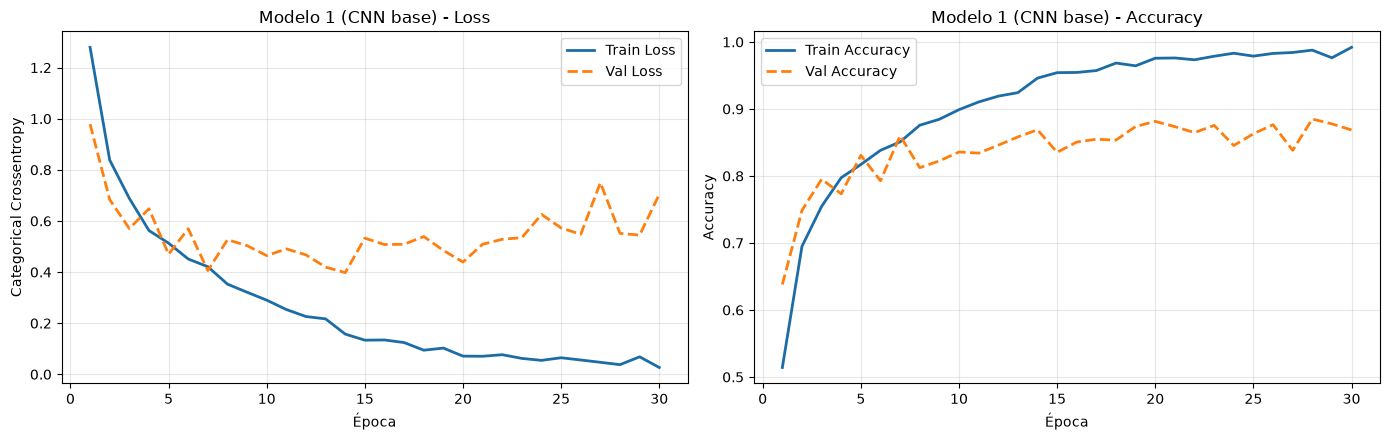


✓ [Modelo 1 (CNN base)] Train 99.20% | Val 86.86% | Test 85.38% | 1,143,242 parámetros | 89 s


In [7]:
def build_cnn(n_blocks=3, base_filters=32, kernel_size=3, convs_per_block=1, head="flatten",
              dense_units=128, batch_norm=False, dropout_conv=0.0, dropout_dense=0.0, l2=0.0,
              augmentation=None, name="cnn"):
    """Construye una CNN de `n_blocks` bloques [Conv2D x convs_per_block -> MaxPooling2D].
    El bloque b tiene base_filters * 2**b filtros. head: "flatten" o "gap" (GlobalAveragePooling)."""
    reg = regularizers.l2(l2) if l2 > 0 else None
    inputs = keras.Input(shape=IMG_SHAPE)
    x = augmentation(inputs) if augmentation is not None else inputs  # solo actúa al entrenar
    for b in range(n_blocks):
        filters = base_filters * 2 ** b
        for c in range(convs_per_block):
            # con BatchNorm el sesgo de la convolución sobra: BN ya aprende un desplazamiento (beta)
            x = layers.Conv2D(filters, kernel_size, padding="same", use_bias=not batch_norm,
                              kernel_regularizer=reg, name=f"conv{b + 1}_{c + 1}")(x)
            if batch_norm:
                x = layers.BatchNormalization(name=f"bn{b + 1}_{c + 1}")(x)
            x = layers.Activation("relu", name=f"relu{b + 1}_{c + 1}")(x)
        x = layers.MaxPooling2D(2, name=f"pool{b + 1}")(x)
        if dropout_conv > 0:
            x = layers.Dropout(dropout_conv, name=f"drop_conv{b + 1}")(x)
    x = layers.Flatten(name="flatten")(x) if head == "flatten" else layers.GlobalAveragePooling2D(name="gap")(x)
    if dropout_dense > 0:
        x = layers.Dropout(dropout_dense, name="drop_dense1")(x)
    x = layers.Dense(dense_units, activation="relu", kernel_regularizer=reg, name="dense")(x)
    if dropout_dense > 0:
        x = layers.Dropout(dropout_dense, name="drop_dense2")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="output")(x)
    return keras.Model(inputs, outputs, name=name)

reset_seed()
model_1 = build_cnn(n_blocks=3, base_filters=32, kernel_size=3, name="Modelo_1_CNN_Base")
model_1.summary()
history_1 = run_experiment("Modelo 1 (CNN base)", model_1, epochs=30)

### Comentarios del Modelo 1 (CNN base)
* **Mejora inmediata respecto a la P1:** la CNN más sencilla, sin ninguna regularización, alcanza un **85,38% en test**, frente al 65,09% del mejor MLP de la P1 (+20 puntos), con **1,14 M de parámetros frente a 6,46 M** (5,6 veces menos). La red ve la imagen como un mapa 2D: cada filtro de 3x3 combina píxeles vecinos y los mismos pesos se aplican en todas las posiciones, así que un borde o una textura se detecta esté donde esté. El MLP tenía que aprender cada patrón por separado en cada posición del vector aplanado.
* **Sobreajuste claro:** la pérdida de validación alcanza su mínimo hacia las épocas 10-20 (~0,44) y después sube hasta 0,70 en la época 30, mientras la de entrenamiento baja hasta 0,024. Al final, entrenamiento 99,20% frente a validación 86,86%: **brecha de 12,3 puntos**.
* **Dónde está el sobreajuste:** la capa `Dense(128)` que va tras el `Flatten` recibe $8 \cdot 8 \cdot 128 = 8.192$ valores, lo que da $8.192 \cdot 128 + 128 = 1.048.704$ pesos: el **92% de los parámetros de la red** están en esa capa. Es la parte que memoriza, y la búsqueda de arquitectura de la sección 6 actúa sobre ella.

<a id="sec6"></a>
## 6. Búsqueda de la Arquitectura

El enunciado pide **determinar la mejor arquitectura** (capas convolucionales, capas de agrupación, número de filtros, tamaño de los kernels...). Comparamos variantes que cambian **un hiperparámetro cada vez** respecto a la red base (B), para saber a qué se debe cada diferencia:

| Variante | Qué cambia | Para qué |
|---|---|---|
| A | 2 bloques | Red menos profunda: campo receptivo menor y mapa final de 16x16 (más parámetros en la densa) |
| **B** | 3 bloques, 32 filtros, kernel 3x3 (= Modelo 1) | Referencia |
| C | 4 bloques | Más profundidad: patrones más abstractos y mapa final de 4x4 |
| D | Kernel 5x5 | Cada filtro ve una zona mayor, con más parámetros por filtro |
| E | 64 filtros de base | Doble de filtros (anchura) en todos los bloques |
| F | 2 convoluciones por bloque (estilo VGG) | Dos 3x3 seguidas ven 5x5 con menos parámetros y una no linealidad más |
| G | 4 bloques x 2 convoluciones | Combina profundidad y bloques VGG |
| H | F con `GlobalAveragePooling` en lugar de `Flatten` | Cabeza con muchos menos parámetros |

**Protocolo:** cada variante se entrena hasta 20 épocas con Adam ($10^{-3}$) y *Early Stopping* (paciencia 5, recuperando los mejores pesos según `val_loss`), sin regularización, para comparar la capacidad de cada arquitectura en igualdad de condiciones. Se elige por la **exactitud de validación**. En esta fase no se mide el test.

In [8]:
ARCH_CONFIGS = {
    "A: 2 bloques, 32f, k3":          dict(n_blocks=2, base_filters=32, kernel_size=3),
    "B: 3 bloques, 32f, k3 (base)":   dict(n_blocks=3, base_filters=32, kernel_size=3),
    "C: 4 bloques, 32f, k3":          dict(n_blocks=4, base_filters=32, kernel_size=3),
    "D: 3 bloques, 32f, k5":          dict(n_blocks=3, base_filters=32, kernel_size=5),
    "E: 3 bloques, 64f, k3":          dict(n_blocks=3, base_filters=64, kernel_size=3),
    "F: 3 bloques x2 conv, 32f, k3":  dict(n_blocks=3, base_filters=32, kernel_size=3, convs_per_block=2),
    "G: 4 bloques x2 conv, 32f, k3":  dict(n_blocks=4, base_filters=32, kernel_size=3, convs_per_block=2),
    "H: 3 bloques x2 conv, GAP":      dict(n_blocks=3, base_filters=32, kernel_size=3, convs_per_block=2, head="gap"),
}

arch_results = {}
for arch_name, cfg in ARCH_CONFIGS.items():
    reset_seed()
    m = build_cnn(**cfg, name="arquitectura")
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="categorical_crossentropy", metrics=["accuracy"])
    es = callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    start = time.time()
    h = m.fit(train_ds, validation_data=val_ds, epochs=20, callbacks=[es], verbose=0)
    elapsed = time.time() - start
    va_loss, va_acc = m.evaluate(val_ds, verbose=0)
    best_epoch = int(np.argmin(h.history["val_loss"])) + 1
    arch_results[arch_name] = {
        "Parámetros": m.count_params(),
        "Mejor época": best_epoch,
        "Train Acc (%) en esa época": round(h.history["accuracy"][best_epoch - 1] * 100, 2),
        "Val Acc (%)": round(va_acc * 100, 2),
        "Val Loss": round(va_loss, 4),
        "Tiempo (s)": round(elapsed, 1),
    }
    print(f"{arch_name:34s} -> val_acc {va_acc*100:.2f}% | {m.count_params():>9,} parámetros | "
          f"mejor época {best_epoch} | {elapsed:.0f} s")

df_arch = pd.DataFrame(arch_results).T
display(df_arch)

A: 2 bloques, 32f, k3              -> val_acc 82.42% | 2,117,962 parámetros | mejor época 7 | 35 s


B: 3 bloques, 32f, k3 (base)       -> val_acc 87.88% | 1,143,242 parámetros | mejor época 15 | 51 s


C: 4 bloques, 32f, k3              -> val_acc 90.22% |   914,122 parámetros | mejor época 12 | 52 s


D: 3 bloques, 32f, k5              -> val_acc 81.78% | 1,308,618 parámetros | mejor época 7 | 42 s


E: 3 bloques, 64f, k3              -> val_acc 87.16% | 2,469,386 parámetros | mejor época 12 | 80 s


F: 3 bloques x2 conv, 32f, k3      -> val_acc 88.81% | 1,337,002 parámetros | mejor época 10 | 68 s


G: 4 bloques x2 conv, 32f, k3      -> val_acc 88.17% | 1,697,962 parámetros | mejor época 12 | 83 s


H: 3 bloques x2 conv, GAP          -> val_acc 91.70% |   304,810 parámetros | mejor época 19 | 85 s


,Parámetros,Mejor época,Train Acc (%) en esa época,Val Acc (%),Val Loss,Tiempo (s)
"A: 2 bloques, 32f, k3",2117962.0,7.0,86.14,82.42,0.4973,35.2
"B: 3 bloques, 32f, k3 (base)",1143242.0,15.0,95.17,87.88,0.3854,51.2
"C: 4 bloques, 32f, k3",914122.0,12.0,92.28,90.22,0.2943,52.4
"D: 3 bloques, 32f, k5",1308618.0,7.0,85.42,81.78,0.5122,42.1
"E: 3 bloques, 64f, k3",2469386.0,12.0,94.68,87.16,0.4027,80.2
"F: 3 bloques x2 conv, 32f, k3",1337002.0,10.0,94.37,88.81,0.3630,68.4
"G: 4 bloques x2 conv, 32f, k3",1697962.0,12.0,94.99,88.17,0.3823,83.4
"H: 3 bloques x2 conv, GAP",304810.0,19.0,92.98,91.70,0.2250,85.0


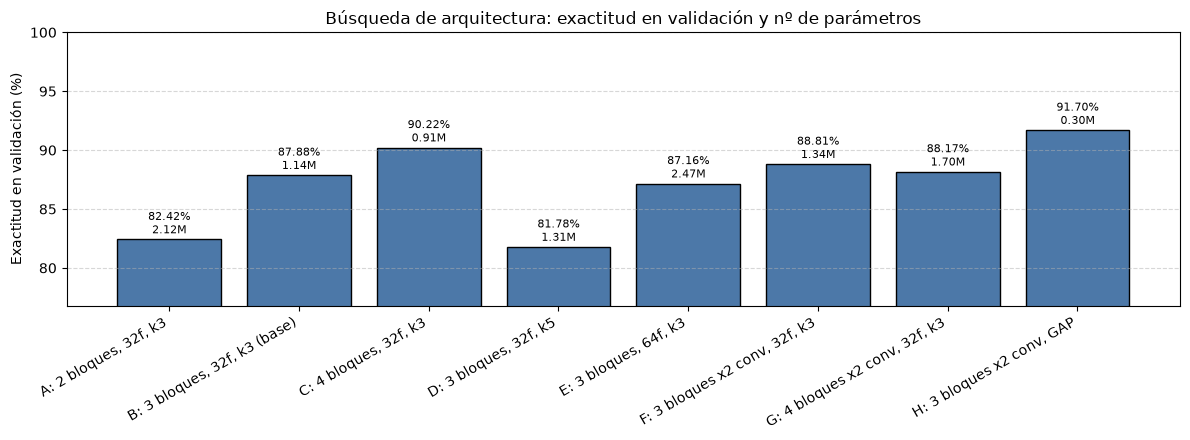

Arquitectura elegida (mayor exactitud en validación): H: 3 bloques x2 conv, GAP -> {'n_blocks': 3, 'base_filters': 32, 'kernel_size': 3, 'convs_per_block': 2, 'head': 'gap'}


In [9]:
fig, ax = plt.subplots(figsize=(12, 4.5))
bars = ax.bar(df_arch.index, df_arch["Val Acc (%)"], color="#4c78a8", edgecolor="black")
for bar, params in zip(bars, df_arch["Parámetros"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.2,
            f"{bar.get_height():.2f}%\n{params/1e6:.2f}M", ha="center", va="bottom", fontsize=8)
ax.set_ylim(df_arch["Val Acc (%)"].min() - 5, 100)
ax.set_ylabel("Exactitud en validación (%)")
ax.set_title("Búsqueda de arquitectura: exactitud en validación y nº de parámetros")
ax.set_xticks(range(len(df_arch)))
ax.set_xticklabels(df_arch.index, rotation=30, ha="right")
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

best_arch_name = df_arch["Val Acc (%)"].astype(float).idxmax()
BEST_ARCH = ARCH_CONFIGS[best_arch_name]
print(f"Arquitectura elegida (mayor exactitud en validación): {best_arch_name} -> {BEST_ARCH}")

### Comentarios de la búsqueda de arquitectura
* **Profundidad:** pasar de 2 a 3 y a 4 bloques mejora la validación (82,42% → 87,88% → 90,22%) y, aunque parezca contradictorio, **reduce los parámetros** (2,12 M → 1,14 M → 0,91 M). Cada `MaxPooling` divide el mapa entre 2 en alto y ancho, de modo que el `Flatten` final es más pequeño (16x16x64 con 2 bloques, 4x4x256 con 4). Además, con más bloques cada neurona del final ve una zona mayor de la imagen (campo receptivo).
* **Kernel 5x5 (D):** es la peor variante (81,78%). Tiene más parámetros por filtro y sobreajusta antes (mejor época: 7). En imágenes de 64x64 con texturas finas, los filtros 3x3 apilados bastan para cubrir zonas grandes.
* **Más filtros (E, 64 de base):** no mejora a B (87,16% frente a 87,88%) y duplica los parámetros (2,47 M). Al problema no le falta capacidad; le sobra.
* **Bloques VGG con dos convoluciones (F, G):** dos 3x3 seguidas cubren una zona de 5x5 con menos pesos y una ReLU más. F mejora a B (88,81%), pero G no mejora a C (88,17% frente a 90,22%): con la cabeza `Flatten` el límite lo pone el sobreajuste de la capa densa, no la parte convolucional.
* **GlobalAveragePooling (H): la ganadora**, con 91,70% en validación y la menor pérdida de validación (0,225), **con solo 0,30 M de parámetros**, 3,7 veces menos que la base. GAP sustituye cada mapa de 8x8 por su media, así que la capa densa recibe 128 valores en lugar de 8.192. Desaparece casi todo el millón de pesos que memorizaba y la red sobreajusta más tarde: su mejor época es la 19, la más tardía de todas. Funciona como un regularizador de la propia arquitectura.
* **Robustez de la elección:** las diferencias de ~1 punto entre variantes cercanas cambian de una ejecución a otra por el no determinismo de la GPU. En una ejecución anterior de este cuaderno, F y G intercambiaron su orden, pero **H ganó también, con un 91,53%**: su ventaja de ~1,5 puntos sobre la segunda es estable.

<a id="sec7"></a>
## 7. Experimentación con Medidas de Regularización

Partimos de la arquitectura elegida (`BEST_ARCH`) y añadimos **una medida de regularización cada vez**, igual que en la P1, para medir el efecto de cada una por separado. Todos los modelos de esta sección se entrenan **40 épocas sin Early Stopping**, para ver la forma completa de las curvas: si la pérdida de validación sube (sobreajuste) o no.

---
### 7.1. Modelo 2: Arquitectura elegida sin regularización (referencia)
Es la referencia de esta sección: muestra cuánto sobreajusta la arquitectura elegida cuando se entrena 40 épocas sin ningún control.

Model: "Modelo_2_Arquitectura_Elegida"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_1 (Conv2D)                │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1_1 (Activation)            │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_2 (Conv2D)                │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1_2 (Activation)            │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_1 (Conv2D)                │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2_1 (Activation)            │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_2 (Conv2D)                │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2_2 (Activation)            │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3_1 (Conv2D)                │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3_1 (Activation)            │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3_2 (Conv2D)                │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3_2 (Activation)            │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 304,810 (1.16 MB)

 Trainable params: 304,810 (1.16 MB)

 Non-trainable params: 0 (0.00 B)

Época   1 | loss 1.5403 acc 0.3798 | val_loss 1.3106 val_acc 0.4585


... (4 outputs left out)

Época  25 | loss 0.1429 acc 0.9505 | val_loss 0.2240 val_acc 0.9244


Época  30 | loss 0.1021 acc 0.9652 | val_loss 0.1790 val_acc 0.9449


Época  35 | loss 0.0926 acc 0.9674 | val_loss 0.1723 val_acc 0.9454


Época  40 | loss 0.0642 acc 0.9781 | val_loss 0.1784 val_acc 0.9486


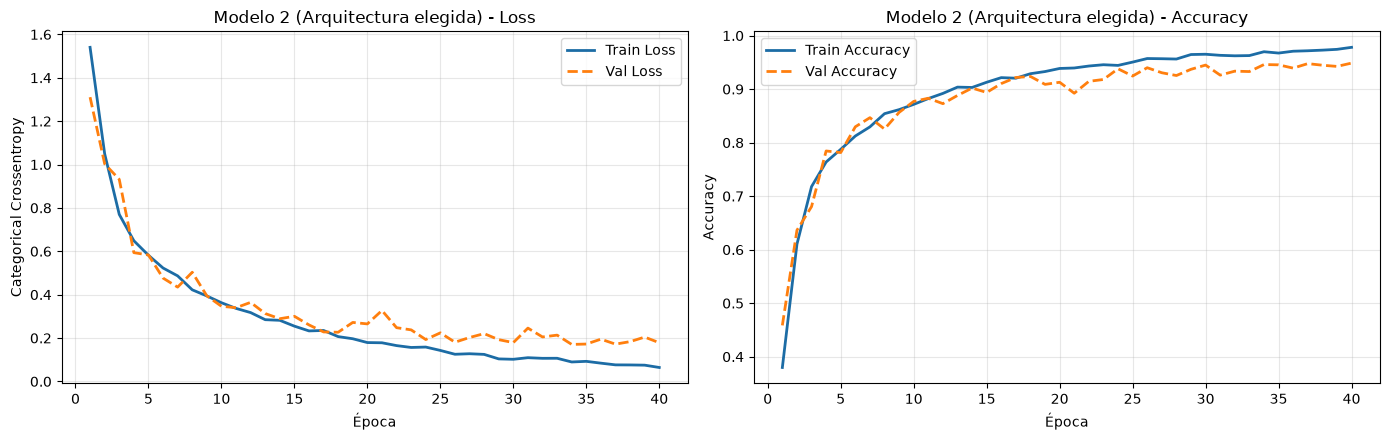


✓ [Modelo 2 (Arquitectura elegida)] Train 98.48% | Val 94.86% | Test 95.16% | 304,810 parámetros | 163 s


In [10]:
reset_seed()
model_2 = build_cnn(**BEST_ARCH, name="Modelo_2_Arquitectura_Elegida")
model_2.summary()
history_2 = run_experiment("Modelo 2 (Arquitectura elegida)", model_2, epochs=40)

### Comentarios del Modelo 2
* Con 40 épocas, la arquitectura H llega a **94,86% en validación y 95,16% en test**: casi 10 puntos más que el Modelo 1, con 3,7 veces menos parámetros.
* La **brecha baja de 12,3 a 3,6 puntos**, sin ninguna medida de regularización: es el efecto de quitar la capa densa enorme (GAP).
* La pérdida de validación baja hasta ~0,172 en la época 35 y repunta ligeramente en la 40 (0,178): el **sobreajuste empieza, pero es leve**. Esta es la referencia de la sección: cada regularizador debe reducir la brecha sin perder exactitud.

---
### 7.2. Modelo 3: Aumento de Datos (Data Augmentation)

El **aumento de datos** genera en cada época versiones transformadas al azar de las imágenes de entrenamiento. La red casi nunca ve dos veces la misma imagen exacta, así que le cuesta más memorizar. Usamos las capas de preprocesado de Keras (como en el Laboratorio 6), colocadas al principio del modelo: **solo actúan durante el entrenamiento** y se desactivan al evaluar o predecir.

Elegimos transformaciones que **no cambian la clase** de una imagen de satélite:
* `RandomFlip("horizontal_and_vertical")`: una imagen tomada desde arriba no tiene un "arriba" natural. Un río o un bosque reflejados siguen siendo un río o un bosque. (En fotos normales, como gatos y perros, no se usa el volteo vertical.)
* `RandomRotation(0.25)`: giros de hasta ±90°, por el mismo motivo.
* `RandomTranslation(0.1, 0.1)` y `RandomZoom(0.1)`: desplazamientos y zoom de hasta un 10%.
* `fill_mode="reflect"`: los huecos que dejan el giro o el desplazamiento se rellenan reflejando la imagen, en lugar de dejar esquinas negras que no existen en las imágenes reales.

**No** alteramos el color (brillo o contraste), porque el color es una de las pistas principales para separar clases (agua azul oscura frente a vegetación verde, por ejemplo).

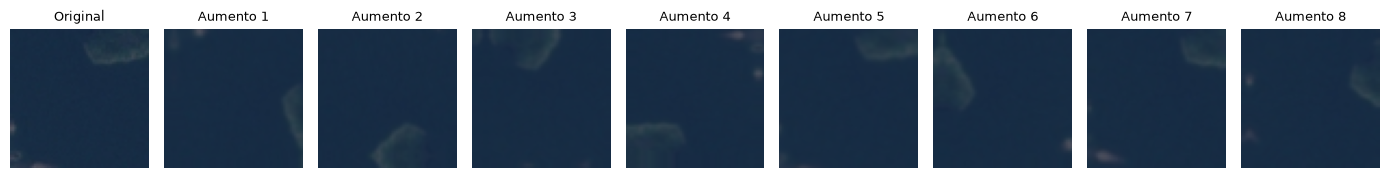

In [11]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.25, fill_mode="reflect"),
    layers.RandomTranslation(0.1, 0.1, fill_mode="reflect"),
    layers.RandomZoom(0.1, fill_mode="reflect"),
], name="data_augmentation")

# Visualizamos 8 versiones aumentadas de una misma imagen de entrenamiento
example = next(iter(train_ds))[0][:1]
plt.figure(figsize=(14, 3.5))
plt.subplot(1, 9, 1); plt.imshow(example[0]); plt.title("Original", fontsize=9); plt.axis("off")
for i in range(8):
    aug = data_augmentation(example, training=True)
    plt.subplot(1, 9, i + 2); plt.imshow(np.clip(aug[0], 0, 1)); plt.title(f"Aumento {i+1}", fontsize=9); plt.axis("off")
plt.tight_layout()
plt.show()

Época   1 | loss 1.6848 acc 0.3441 | val_loss 1.4114 val_acc 0.4659


Época   5 | loss 0.7264 acc 0.7357 | val_loss 0.8332 val_acc 0.7000


Época  10 | loss 0.5053 acc 0.8188 | val_loss 0.7902 val_acc 0.7422


Época  15 | loss 0.3946 acc 0.8589 | val_loss 0.4255 val_acc 0.8479


Época  20 | loss 0.3140 acc 0.8892 | val_loss 0.4101 val_acc 0.8647


Época  25 | loss 0.2709 acc 0.9038 | val_loss 0.3122 val_acc 0.8919


Época  30 | loss 0.2173 acc 0.9247 | val_loss 0.3142 val_acc 0.8911


Época  35 | loss 0.1912 acc 0.9316 | val_loss 0.3249 val_acc 0.8805


Época  40 | loss 0.1694 acc 0.9392 | val_loss 0.3528 val_acc 0.8822


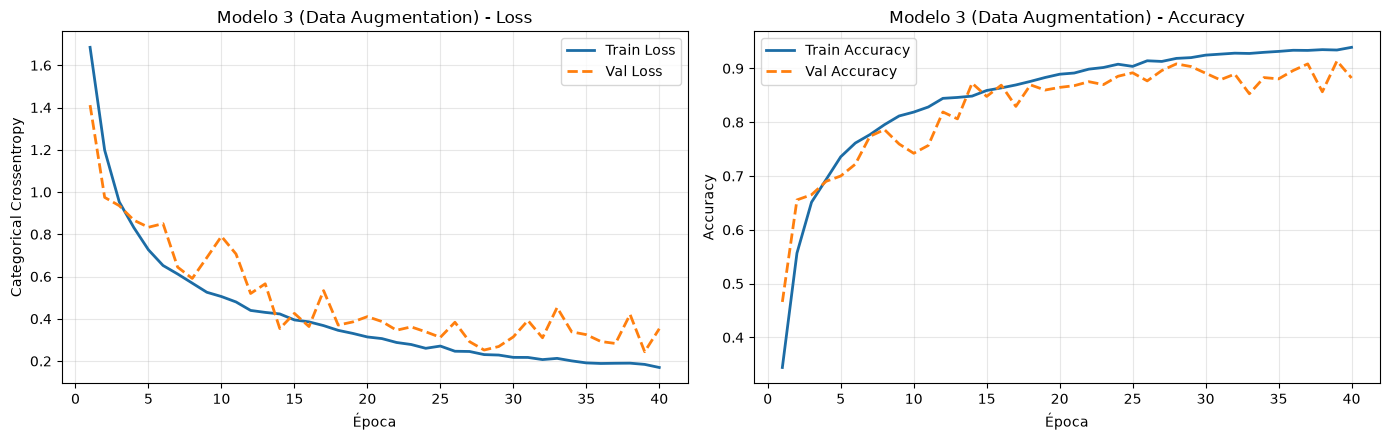


✓ [Modelo 3 (Data Augmentation)] Train 89.24% | Val 88.22% | Test 88.10% | 304,810 parámetros | 294 s


In [12]:
reset_seed()
model_3 = build_cnn(**BEST_ARCH, augmentation=data_augmentation, name="Modelo_3_Data_Augmentation")
history_3 = run_experiment("Modelo 3 (Data Augmentation)", model_3, epochs=40)

### Comentarios del Modelo 3 (Data Augmentation)
* **Elimina el sobreajuste:** la brecha queda en solo **1,0 punto** (entrenamiento 89,24%, validación 88,22%). La red no puede memorizar imágenes que cambian en cada época.
* **Pero a las 40 épocas está en infrajuste:** la exactitud (88,10% en test) es 7 puntos inferior a la del Modelo 2. La exactitud de entrenamiento seguía subiendo al final (93,9% sobre las imágenes aumentadas). Aprender con imágenes que cambian en cada época es más difícil y necesita más épocas.
* La validación oscila (pérdida entre 0,31 y 0,35 en las últimas épocas) y cada época tarda casi el doble (294 s frente a 163 s) por las transformaciones.
* **Conclusión:** es el regularizador más potente contra el sobreajuste, pero hay que darle muchas más épocas. Lo tenemos en cuenta en la sección 8.

---
### 7.3. Modelo 4: Dropout

**Dropout** pone a cero al azar una fracción $p$ de las activaciones en cada paso de entrenamiento, y así impide que unas neuronas dependan de otras concretas. En la P1, $p = 0.3$ en todas las capas densas provocó infrajuste. Aquí lo colocamos donde una CNN tiene más riesgo de sobreajuste:
* **$p = 0.5$ antes y después de la capa densa**: la parte de clasificación concentra la mayoría de los parámetros.
* **$p = 0.1$ tras cada bloque convolucional**: suave, porque las convoluciones tienen pocos parámetros y comparten pesos.

Época   1 | loss 1.9253 acc 0.2300 | val_loss 1.6576 val_acc 0.3286


Época   5 | loss 0.7473 acc 0.7403 | val_loss 0.6177 val_acc 0.7716


Época  10 | loss 0.4775 acc 0.8469 | val_loss 0.3731 val_acc 0.8733


Época  15 | loss 0.3444 acc 0.8916 | val_loss 0.3119 val_acc 0.8923


Época  20 | loss 0.2801 acc 0.9136 | val_loss 0.2798 val_acc 0.9067


Época  25 | loss 0.2201 acc 0.9305 | val_loss 0.2908 val_acc 0.9054


Época  30 | loss 0.1888 acc 0.9405 | val_loss 0.2093 val_acc 0.9299


Época  35 | loss 0.1546 acc 0.9526 | val_loss 0.2479 val_acc 0.9207


Época  40 | loss 0.1269 acc 0.9589 | val_loss 0.1978 val_acc 0.9400


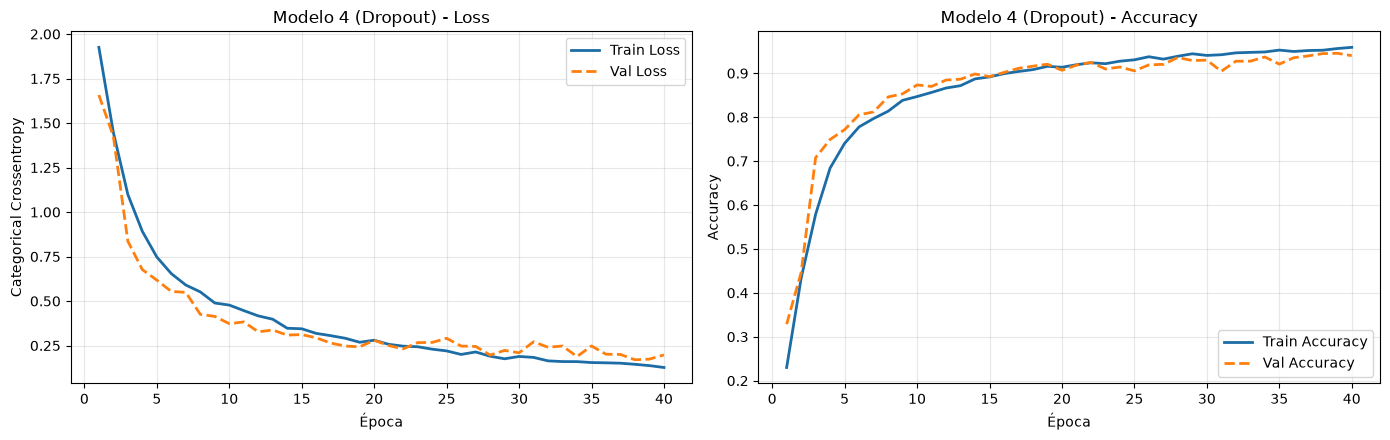


✓ [Modelo 4 (Dropout)] Train 97.31% | Val 94.00% | Test 94.62% | 304,810 parámetros | 167 s


In [13]:
reset_seed()
model_4 = build_cnn(**BEST_ARCH, dropout_conv=0.1, dropout_dense=0.5, name="Modelo_4_Dropout")
history_4 = run_experiment("Modelo 4 (Dropout)", model_4, epochs=40)

### Comentarios del Modelo 4 (Dropout)
* Resultado muy parecido al Modelo 2: **94,00% en validación y 94,62% en test**, con una brecha de 3,3 puntos.
* A diferencia de la P1 (Dropout 0,3 en todas las capas densas → 31% de exactitud), aquí **no provoca infrajuste**. En la CNN el Dropout de las convoluciones es suave (0,1) y la cabeza con GAP es pequeña.
* La pérdida de validación seguía bajando en la época 40 (0,198), así que el modelo aún no había terminado de aprender: frena el aprendizaje un poco, a cambio de una curva de validación más suave que la del Modelo 2.

---
### 7.4. Modelo 5: Batch Normalization

**Batch Normalization** normaliza la salida de cada convolución (media 0 y varianza 1 en el lote) y después la reescala con dos parámetros que se aprenden ($\gamma$ y $\beta$). Va entre la convolución y la ReLU, y la convolución se crea sin sesgo porque $\beta$ ya hace ese papel.

En la P1, BN en la red densa disparó el sobreajuste. En las CNN es la configuración estándar (VGG con BN, ResNet...): la estadística de cada filtro se calcula sobre todas las posiciones del mapa y todas las imágenes del lote, y por eso es mucho más estable que en una capa densa.

Época   1 | loss 0.7651 acc 0.7325 | val_loss 5.0967 val_acc 0.1257


Época   5 | loss 0.2759 acc 0.9035 | val_loss 0.4081 val_acc 0.8649


Época  10 | loss 0.1691 acc 0.9405 | val_loss 1.8255 val_acc 0.5548


Época  15 | loss 0.1204 acc 0.9590 | val_loss 0.4168 val_acc 0.8615


Época  20 | loss 0.1091 acc 0.9639 | val_loss 0.2944 val_acc 0.9096


Época  25 | loss 0.0809 acc 0.9722 | val_loss 2.0641 val_acc 0.5805


Época  30 | loss 0.0588 acc 0.9784 | val_loss 0.9535 val_acc 0.7970


Época  35 | loss 0.0382 acc 0.9869 | val_loss 1.4711 val_acc 0.7212


Época  40 | loss 0.0582 acc 0.9806 | val_loss 0.1617 val_acc 0.9519


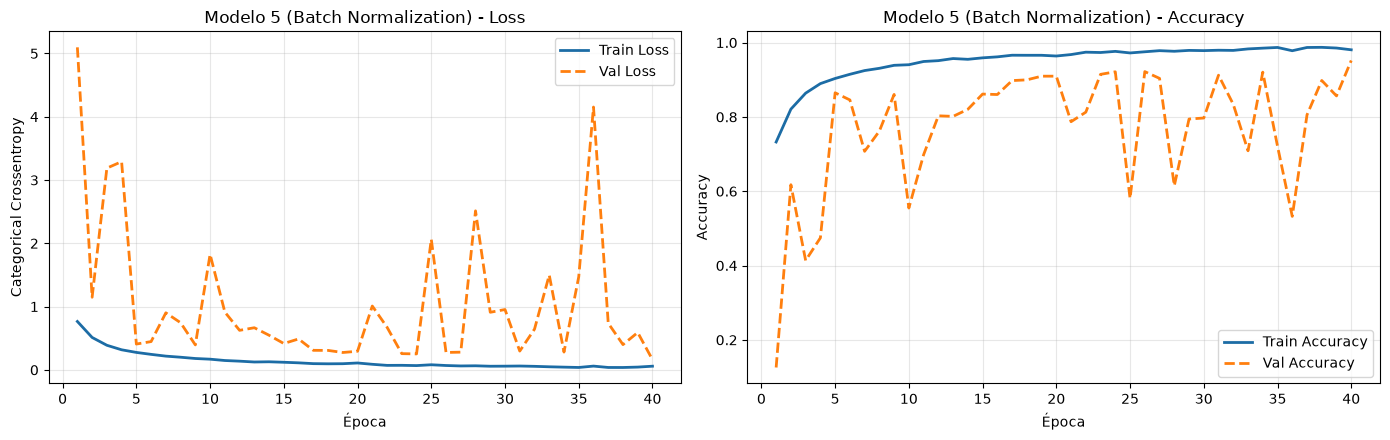


✓ [Modelo 5 (Batch Normalization)] Train 97.37% | Val 95.19% | Test 94.84% | 306,154 parámetros | 183 s


In [14]:
reset_seed()
model_5 = build_cnn(**BEST_ARCH, batch_norm=True, name="Modelo_5_BatchNorm")
history_5 = run_experiment("Modelo 5 (Batch Normalization)", model_5, epochs=40)

### Comentarios del Modelo 5 (Batch Normalization)
* **Aprendizaje mucho más rápido:** en la época 1 la exactitud de entrenamiento ya es del 73% (38% sin BN), y al final llega a **95,19% en validación y 94,84% en test**, la mejor validación de esta sección.
* **Validación muy inestable:** 12,6% de exactitud en la época 1, 55,5% en la 10, 58,1% en la 25, 72,1% en la 35 y 95,2% en la 40. En inferencia, BN normaliza con **medias móviles** (`momentum=0.99`, que en la práctica promedia los ~100 últimos lotes). Esas medias se calculan mientras los pesos cambian deprisa con $\eta = 10^{-3}$, así que se quedan atrás y no corresponden a la red actual. En entrenamiento BN usa la media del lote actual, y por eso la curva de entrenamiento es suave y la de validación no.
* **Lectura crítica:** el 95,19% depende en parte de en qué época se paró: 5 épocas antes la red daba un 72%. En la P1, BN en la red densa hizo diverger la validación sin remedio; aquí la red se recupera, pero la inestabilidad hace que BN **no sea fiable si no se reduce la tasa de aprendizaje** al final.

---
### 7.5. Modelo 6: Regularización $L_2$

Añade a la pérdida $\lambda \sum_j w_j^2$ sobre los pesos de las convoluciones y de la capa densa oculta, con $\lambda = 10^{-4}$ (el valor que en la P1 redujo la brecha sin infrajuste).

Época   1 | loss 1.5619 acc 0.3715 | val_loss 1.2897 val_acc 0.4805


Época   5 | loss 0.6649 acc 0.7739 | val_loss 0.6416 val_acc 0.7783


Época  10 | loss 0.5131 acc 0.8346 | val_loss 0.5493 val_acc 0.8254


Época  15 | loss 0.3984 acc 0.8806 | val_loss 0.4212 val_acc 0.8768


Época  20 | loss 0.3127 acc 0.9111 | val_loss 0.3898 val_acc 0.8886


Época  25 | loss 0.2702 acc 0.9276 | val_loss 0.3232 val_acc 0.9126


Época  30 | loss 0.2421 acc 0.9376 | val_loss 0.3237 val_acc 0.9106


Época  35 | loss 0.2110 acc 0.9486 | val_loss 0.2700 val_acc 0.9311


Época  40 | loss 0.1843 acc 0.9599 | val_loss 0.2655 val_acc 0.9356


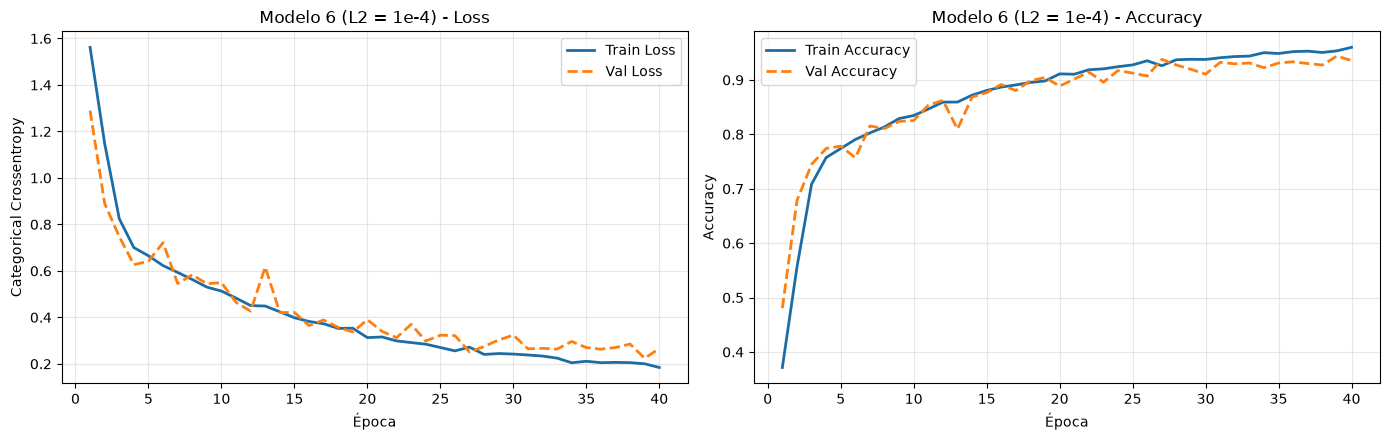


✓ [Modelo 6 (L2 = 1e-4)] Train 95.31% | Val 93.56% | Test 93.78% | 304,810 parámetros | 165 s


In [15]:
reset_seed()
model_6 = build_cnn(**BEST_ARCH, l2=1e-4, name="Modelo_6_L2")
history_6 = run_experiment("Modelo 6 (L2 = 1e-4)", model_6, epochs=40)

### Comentarios del Modelo 6 ($L_2$)
* Entrenamiento 95,31%, validación 93,56%, test 93,78%: **la brecha se reduce a la mitad** (1,75 frente a 3,6 puntos del Modelo 2), pero con 1,3 puntos menos de validación.
* Penalizar los pesos grandes frena el aprendizaje: la pérdida de validación seguía bajando en la época 40 (0,266). Como en la P1, $L_2$ cambia exactitud por estabilidad.

<a id="sec8"></a>
## 8. Optimización y Modelo Final

### 8.1. Modelo 7: Combinación final (Adam + ReduceLROnPlateau + Early Stopping)

Combinamos las medidas que han funcionado por separado, teniendo en cuenta lo aprendido en la P1:
1. **Aumento de datos** (sección 7.2).
2. **Batch Normalization** en los bloques convolucionales (sección 7.4).
3. **Dropout $p=0.5$ solo en la cabeza densa**, no tras las convoluciones. En la P1, Dropout y BN juntos en las mismas capas chocaron (*variance shift*): Dropout cambia la varianza de las activaciones entre entrenamiento e inferencia y BN se queda con estadísticas que ya no corresponden. Si el Dropout va después de la última BN, ese conflicto no existe.
4. **$L_2 = 10^{-4}$** (sección 7.5).

Y dos medidas de **optimización**:
* **`ReduceLROnPlateau`**: si `val_loss` no mejora en 4 épocas, divide la tasa de aprendizaje entre 2. Al principio se dan pasos grandes para avanzar rápido y al final pasos pequeños para afinar. En la P1 vimos que con una tasa fija el optimizador oscilaba al final (*overshooting*).
* **`EarlyStopping`** con paciencia 12 y `restore_best_weights=True`. La paciencia es mayor que en la P1 porque con aumento de datos la mejora es más lenta y ruidosa. Damos hasta 100 épocas.

Model: "Modelo_7_Final_Adam"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_15 (InputLayer)     │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_1 (Conv2D)                │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1_1 (BatchNormalization)      │ (None, 64, 64, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1_1 (Activation)            │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_2 (Conv2D)                │ (None, 64, 64, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1_2 (BatchNormalization)      │ (None, 64, 64, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1_2 (Activation)            │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_1 (Conv2D)                │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2_1 (BatchNormalization)      │ (None, 32, 32, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2_1 (Activation)            │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_2 (Conv2D)                │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2_2 (BatchNormalization)      │ (None, 32, 32, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2_2 (Activation)            │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3_1 (Conv2D)                │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3_1 (BatchNormalization)      │ (None, 16, 16, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3_1 (Activation)            │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3_2 (Conv2D)                │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3_2 (BatchNormalization)      │ (None, 16, 16, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3_2 (Activation)            │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_dense1 (Dropout)           │ (None, 128)            │             

 Total params: 306,154 (1.17 MB)

 Trainable params: 305,258 (1.16 MB)

 Non-trainable params: 896 (3.50 KB)

Época   1 | loss 1.4106 acc 0.5351 | val_loss 2.1445 val_acc 0.3301


... (9 outputs left out)

Época  50 | loss 0.2000 acc 0.9553 | val_loss 0.3219 val_acc 0.9096


Época  55 | loss 0.1972 acc 0.9580 | val_loss 0.2876 val_acc 0.9215


Época  58 | loss 0.1904 acc 0.9594 | val_loss 0.2911 val_acc 0.9207
Epoch 58: early stopping


Restoring model weights from the end of the best epoch: 46.


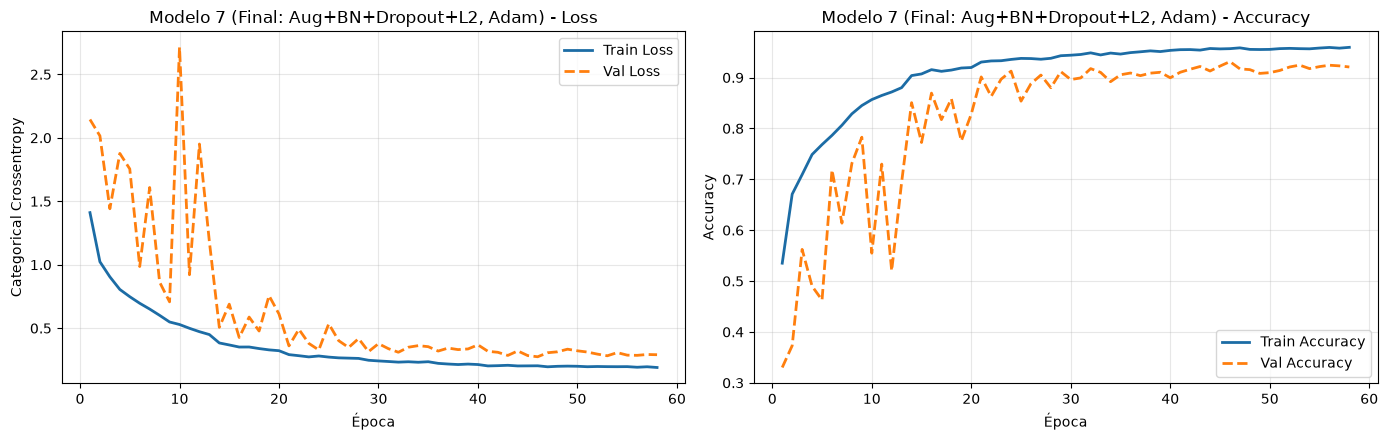


✓ [Modelo 7 (Final: Aug+BN+Dropout+L2, Adam)] Train 93.19% | Val 93.14% | Test 92.57% | 306,154 parámetros | 664 s


In [16]:
FINAL_CFG = dict(BEST_ARCH, batch_norm=True, dropout_dense=0.5, l2=1e-4)

def final_callbacks():
    return [
        callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6, verbose=0),
        callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True, verbose=1),
    ]

reset_seed()
model_7 = build_cnn(**FINAL_CFG, augmentation=data_augmentation, name="Modelo_7_Final_Adam")
model_7.summary()
history_7 = run_experiment("Modelo 7 (Final: Aug+BN+Dropout+L2, Adam)", model_7, epochs=100,
                           optimizer=keras.optimizers.Adam(1e-3), extra_callbacks=final_callbacks())

### Comentarios del Modelo 7 (combinación final con Adam)
* **Peor que el Modelo 2:** 93,14% en validación y 92,57% en test. `EarlyStopping` paró en la época 58 y recuperó los pesos de la 46.
* **Brecha prácticamente nula (0,05 puntos), pero por infrajuste:** la exactitud de entrenamiento con los pesos finales es solo del 93,19%. Aumento de datos, BN, Dropout 0,5 y $L_2$ a la vez dejan a la red sin capacidad suficiente.
* La validación vuelve a dar saltos por BN (55% de exactitud en la época 10, 46% en la 5), lo que dificulta el trabajo de `ReduceLROnPlateau` y `EarlyStopping`. Este modelo tardó 664 s, cuatro veces más que el Modelo 2, para un resultado peor.

---
### 8.2. Modelo 8: Misma red con SGD + momento de Nesterov

Para comprobar el efecto del **optimizador**, entrenamos exactamente la misma red con **SGD con momento** ($\beta = 0.9$, variante de Nesterov) y $\eta = 10^{-2}$, una tasa diez veces mayor que la de Adam porque SGD no adapta el paso a cada peso. Los callbacks son los mismos.

* **Adam** adapta la tasa de cada peso según la media de sus gradientes y de sus cuadrados: suele converger más rápido y depende menos de la tasa inicial.
* **SGD con momento** aplica la misma tasa a todos los pesos y acumula la dirección de los pasos anteriores. Suele necesitar más épocas, pero a veces generaliza algo mejor.

Época   1 | loss 1.4122 acc 0.5247 | val_loss 1.9254 val_acc 0.3736


Época   5 | loss 0.7847 acc 0.7486 | val_loss 0.8605 val_acc 0.7079


Época  10 | loss 0.5315 acc 0.8431 | val_loss 0.4809 val_acc 0.8420


Época  15 | loss 0.4231 acc 0.8863 | val_loss 0.4772 val_acc 0.8625


Época  20 | loss 0.3626 acc 0.9038 | val_loss 0.6345 val_acc 0.8294


Época  25 | loss 0.3402 acc 0.9113 | val_loss 0.4601 val_acc 0.8785


... (4 outputs left out)

Época  50 | loss 0.2581 acc 0.9360 | val_loss 0.3082 val_acc 0.9114


Época  55 | loss 0.2593 acc 0.9378 | val_loss 0.3035 val_acc 0.9148


Época  59 | loss 0.2543 acc 0.9381 | val_loss 0.2957 val_acc 0.9158
Epoch 59: early stopping


Restoring model weights from the end of the best epoch: 47.


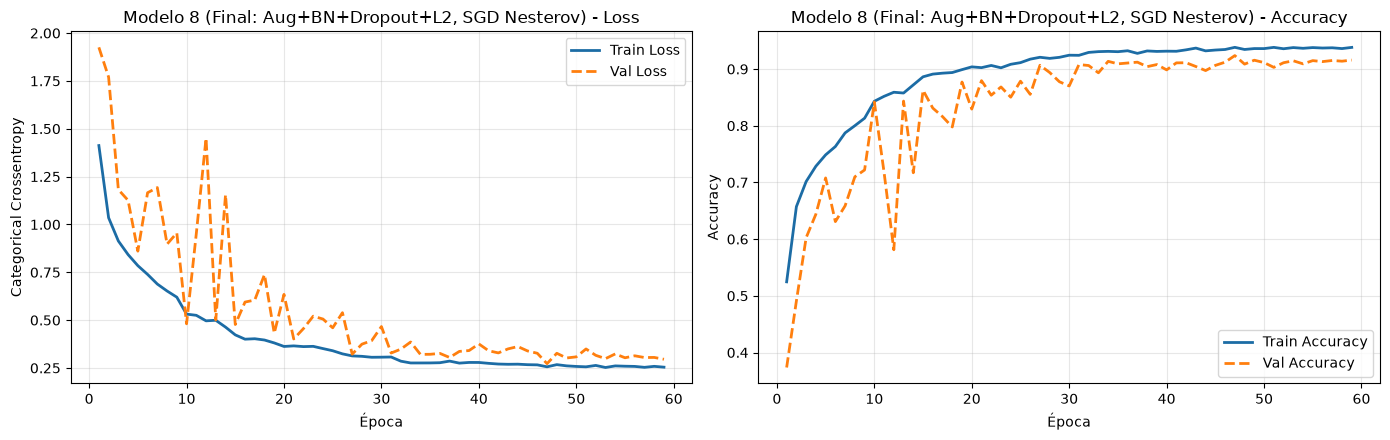


✓ [Modelo 8 (Final: Aug+BN+Dropout+L2, SGD Nesterov)] Train 92.94% | Val 92.37% | Test 92.84% | 306,154 parámetros | 585 s


In [17]:
reset_seed()
model_8 = build_cnn(**FINAL_CFG, augmentation=data_augmentation, name="Modelo_8_Final_SGD")
history_8 = run_experiment("Modelo 8 (Final: Aug+BN+Dropout+L2, SGD Nesterov)", model_8, epochs=100,
                           optimizer=keras.optimizers.SGD(learning_rate=1e-2, momentum=0.9, nesterov=True),
                           extra_callbacks=final_callbacks())

### Comentarios del Modelo 8 (SGD + Nesterov)
* Con SGD + Nesterov el resultado es prácticamente el mismo que con Adam: **92,37% en validación y 92,84% en test** (parada en la época 59, mejores pesos de la 47).
* Lo que cambia es la **dinámica**: con SGD la validación es más estable al principio (84% en la época 10 frente al 55% de Adam), porque da pasos más uniformes en todos los pesos. Pero el límite es el mismo, así que **el problema no es el optimizador, sino la combinación de regularizadores y la forma de parar el entrenamiento**. Lo analizamos a continuación.

---
### 8.3. Diagnóstico de los Modelos 7 y 8 y corrección

Los Modelos 7 y 8 combinan las medidas que funcionaban por separado y, sin embargo, **no superan al Modelo 2**. Las curvas y la tabla muestran tres causas:

1. **Early Stopping engañado por el ruido de validación.** Con Batch Normalization, la pérdida de validación da saltos grandes de una época a otra (ya se veía en el Modelo 5). Las medias móviles que BN usa en inferencia van por detrás de unos pesos que cambian rápido con $\eta = 10^{-3}$. Con esos saltos, `EarlyStopping` y `ReduceLROnPlateau` creen que el modelo ha dejado de mejorar cuando solo es ruido, y el entrenamiento se corta antes de tiempo.
2. **El aumento de datos necesita muchas más épocas.** En el Modelo 3, tras 40 épocas, la exactitud de entrenamiento seguía en ~90% y subiendo: con imágenes distintas en cada época, aprender cuesta más.
3. **Exceso de regularización (infrajuste).** La brecha Train-Val de los Modelos 7 y 8 es casi nula, pero porque la exactitud de **entrenamiento** es baja: aumento de datos, Dropout 0.5 y $L_2$ a la vez limitan demasiado la red. Es el mismo fenómeno que en el Modelo 3 de la P1.

**Corrección (Modelos 9 y 10):**
* **Programa de tasa de aprendizaje fijo**, en lugar de reaccionar a una validación ruidosa. 3 épocas de **calentamiento** (la tasa sube de 0 a $10^{-3}$, para que BN estime bien sus estadísticas al principio) y después **decaimiento coseno** hasta 0 a lo largo de **100 épocas**. Al final la tasa es casi 0, los pesos apenas cambian y la validación se estabiliza, así que se usan los pesos de la última época, sin Early Stopping.
* **Menos regularización explícita:** se quita $L_2$ y el Dropout de la cabeza baja a $p = 0.3$. El aumento de datos ya es un regularizador fuerte.
* Probamos la corrección **con BN** (Modelo 9) y **sin BN** (Modelo 10, con el Dropout del Modelo 4), para saber si BN aporta algo cuando el entrenamiento es largo.

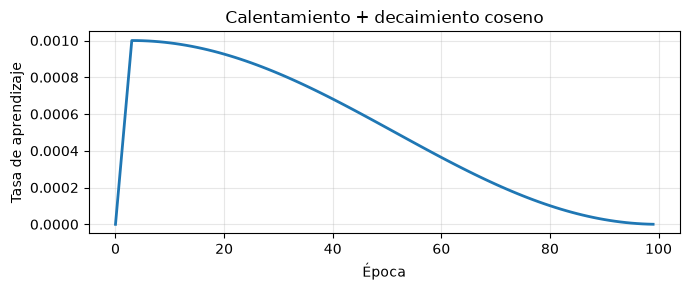

Época   1 | loss 1.5560 acc 0.4725 | val_loss 2.7278 val_acc 0.1565


Época   5 | loss 0.6220 acc 0.7873 | val_loss 1.6530 val_acc 0.5286


Época  10 | loss 0.3443 acc 0.8858 | val_loss 1.2475 val_acc 0.6575


Época  15 | loss 0.2712 acc 0.9117 | val_loss 0.5501 val_acc 0.8163


Época  20 | loss 0.2137 acc 0.9274 | val_loss 0.4021 val_acc 0.8704


Época  25 | loss 0.1874 acc 0.9374 | val_loss 0.3352 val_acc 0.8936


... (11 outputs left out)

Época  85 | loss 0.0619 acc 0.9793 | val_loss 0.1568 val_acc 0.9427


Época  90 | loss 0.0581 acc 0.9802 | val_loss 0.1193 val_acc 0.9570


Época  95 | loss 0.0567 acc 0.9807 | val_loss 0.1235 val_acc 0.9578


Época 100 | loss 0.0542 acc 0.9816 | val_loss 0.1207 val_acc 0.9570


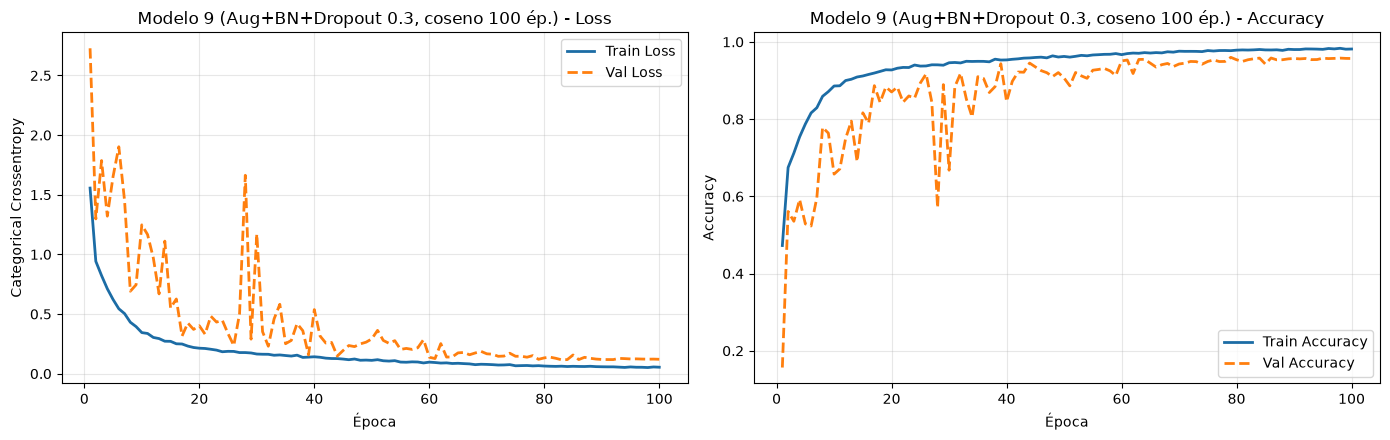


✓ [Modelo 9 (Aug+BN+Dropout 0.3, coseno 100 ép.)] Train 97.02% | Val 95.70% | Test 96.15% | 306,154 parámetros | 1144 s


In [18]:
EPOCHS_LONG = 100
steps_per_epoch = int(train_ds.cardinality())

def cosine_schedule():
    """Calentamiento lineal 3 épocas (0 -> 1e-3) y decaimiento coseno hasta 0 al final de EPOCHS_LONG."""
    warmup = 3 * steps_per_epoch
    return keras.optimizers.schedules.CosineDecay(
        initial_learning_rate=0.0, warmup_target=1e-3, warmup_steps=warmup,
        decay_steps=EPOCHS_LONG * steps_per_epoch - warmup)

lr_curve = cosine_schedule()
steps = np.arange(0, EPOCHS_LONG * steps_per_epoch, steps_per_epoch)
plt.figure(figsize=(7, 3))
plt.plot(steps / steps_per_epoch, [float(lr_curve(s)) for s in steps], lw=2)
plt.xlabel("Época"); plt.ylabel("Tasa de aprendizaje"); plt.title("Calentamiento + decaimiento coseno")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

reset_seed()
model_9 = build_cnn(**dict(BEST_ARCH, batch_norm=True, dropout_dense=0.3), augmentation=data_augmentation,
                    name="Modelo_9_Aug_BN_Coseno")
history_9 = run_experiment("Modelo 9 (Aug+BN+Dropout 0.3, coseno 100 ép.)", model_9, epochs=EPOCHS_LONG,
                           optimizer=keras.optimizers.Adam(learning_rate=cosine_schedule()))

### Comentarios del Modelo 9
* **Es el mejor modelo de este cuaderno: 95,70% en validación y 96,15% en test**, con una brecha de 1,3 puntos y la **menor pérdida de validación de todos** (0,121).
* La curva confirma el diagnóstico. Mientras la tasa de aprendizaje es alta (primera mitad), la validación sigue dando saltos por BN: 66,8% en la época 30, 84,5% en la 40. Cuando la tasa decae (a partir de la época ~60), las medias móviles de BN alcanzan a los pesos y la validación se estabiliza entre el 94% y el 96%. Al final no hace falta elegir una época "afortunada": los pesos de la última época son los buenos.
* **Respecto al Modelo 2:** +0,8 puntos en validación y +1,0 en test, y sobre todo **una pérdida de test mucho menor (0,119 frente a 0,170)**: el modelo se equivoca menos y, cuando acierta, lo hace con más confianza.
* **Coste:** 1.144 s (19 minutos), 7 veces más que el Modelo 2. El aumento de datos encarece cada época y además hacen falta muchas épocas.
* Detalle: la exactitud de entrenamiento medida sin aumento de datos (97,02%) es algo menor que la que se ve durante el entrenamiento con imágenes aumentadas (98,2%). Las medias móviles de BN se calcularon con imágenes giradas y reflejadas, cuya distribución de valores es ligeramente distinta de la de las imágenes originales. La diferencia es pequeña.

E0000 00:00:1794937980.372714     511 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/Modelo_10_Aug_Dropout_Coseno_1/drop_conv1_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


Época   1 | loss 2.0105 acc 0.2216 | val_loss 1.6943 val_acc 0.3269


Época   5 | loss 0.9431 acc 0.6596 | val_loss 0.7749 val_acc 0.7262


Época  10 | loss 0.6544 acc 0.7734 | val_loss 0.7765 val_acc 0.7556


Época  15 | loss 0.4888 acc 0.8372 | val_loss 0.6369 val_acc 0.7849


Época  20 | loss 0.3545 acc 0.8820 | val_loss 0.4309 val_acc 0.8625


... (12 outputs left out)

Época  85 | loss 0.0730 acc 0.9749 | val_loss 0.2726 val_acc 0.9205


Época  90 | loss 0.0730 acc 0.9757 | val_loss 0.3117 val_acc 0.9101


Época  95 | loss 0.0717 acc 0.9759 | val_loss 0.2880 val_acc 0.9193


Época 100 | loss 0.0681 acc 0.9770 | val_loss 0.2864 val_acc 0.9210


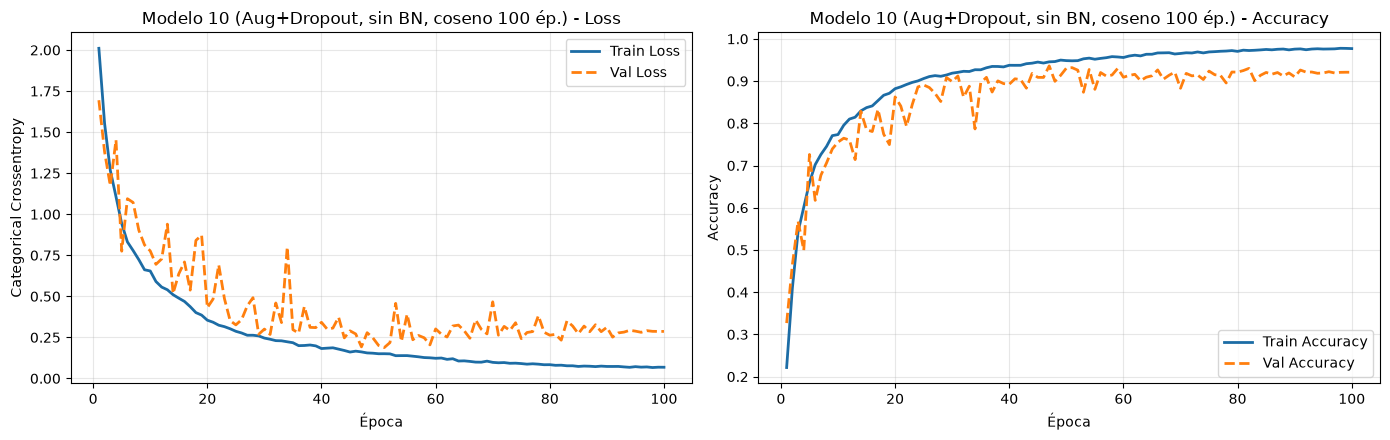


✓ [Modelo 10 (Aug+Dropout, sin BN, coseno 100 ép.)] Train 93.47% | Val 92.10% | Test 92.52% | 304,810 parámetros | 803 s


In [19]:
reset_seed()
model_10 = build_cnn(**dict(BEST_ARCH, dropout_conv=0.1, dropout_dense=0.3), augmentation=data_augmentation,
                     name="Modelo_10_Aug_Dropout_Coseno")
history_10 = run_experiment("Modelo 10 (Aug+Dropout, sin BN, coseno 100 ép.)", model_10, epochs=EPOCHS_LONG,
                            optimizer=keras.optimizers.Adam(learning_rate=cosine_schedule()))

### Comentarios del Modelo 10
* Sin BN, la misma receta se queda en **92,10% en validación y 92,52% en test**: 3,6 puntos menos que el Modelo 9.
* El aprendizaje es mucho más lento (22% en la época 1 frente al 47% con BN) y la validación sigue oscilando al final (pérdida entre 0,24 y 0,47 en las últimas 30 épocas), aunque la tasa sea casi 0.
* **Conclusión:** con un entrenamiento largo y una tasa que decae, **BN es la pieza que marca la diferencia**. Su inestabilidad era un problema de la tasa de aprendizaje, no de BN.
* (El mensaje `layout failed ... TransposeNHWCToNCHW` de la salida es un aviso interno del optimizador de grafos de TensorFlow sobre el Dropout; no afecta al resultado.)

<a id="sec9"></a>
## 9. Comparación Global de Resultados

### 9.1. Tabla resumen de los modelos de esta parte
La **brecha Train-Val** es la diferencia en puntos porcentuales entre la exactitud en entrenamiento y en validación, ambas medidas con los pesos finales y sin aumento de datos ni dropout. Si es grande, el modelo memoriza; si es cercana a 0, generaliza.

TABLA RESUMEN - CNN PERSONALIZADAS EN EUROSAT


,Épocas,Parámetros,Train Acc (%),Val Acc (%),Test Acc (%),Brecha Train-Val (pp),Train Loss,Val Loss,Test Loss,Tiempo (s)
Modelo 1 (CNN base),30.0,1143242.0,99.20,86.86,85.38,12.34,0.0241,0.7043,0.7855,88.7
Modelo 2 (Arquitectura elegida),40.0,304810.0,98.48,94.86,95.16,3.62,0.0456,0.1784,0.1695,162.8
Modelo 3 (Data Augmentation),40.0,304810.0,89.24,88.22,88.10,1.02,0.3216,0.3528,0.3499,294.3
Modelo 4 (Dropout),40.0,304810.0,97.31,94.00,94.62,3.31,0.0773,0.1978,0.1665,167.3
Modelo 5 (Batch Normalization),40.0,306154.0,97.37,95.19,94.84,2.18,0.0724,0.1617,0.1546,183.1
Modelo 6 (L2 = 1e-4),40.0,304810.0,95.31,93.56,93.78,1.75,0.2072,0.2655,0.2591,164.7
"Modelo 7 (Final: Aug+BN+Dropout+L2, Adam)",58.0,306154.0,93.19,93.14,92.57,0.05,0.2674,0.2749,0.2876,663.6
"Modelo 8 (Final: Aug+BN+Dropout+L2, SGD Nesterov)",59.0,306154.0,92.94,92.37,92.84,0.57,0.2686,0.2726,0.2740,584.6
"Modelo 9 (Aug+BN+Dropout 0.3, coseno 100 ép.)",100.0,306154.0,97.02,95.70,96.15,1.32,0.0884,0.1207,0.1190,1144.3
"Modelo 10 (Aug+Dropout, sin BN, coseno 100 ép.)",100.0,304810.0,93.47,92.10,92.52,1.37,0.2399,0.2864,0.2836,802.9


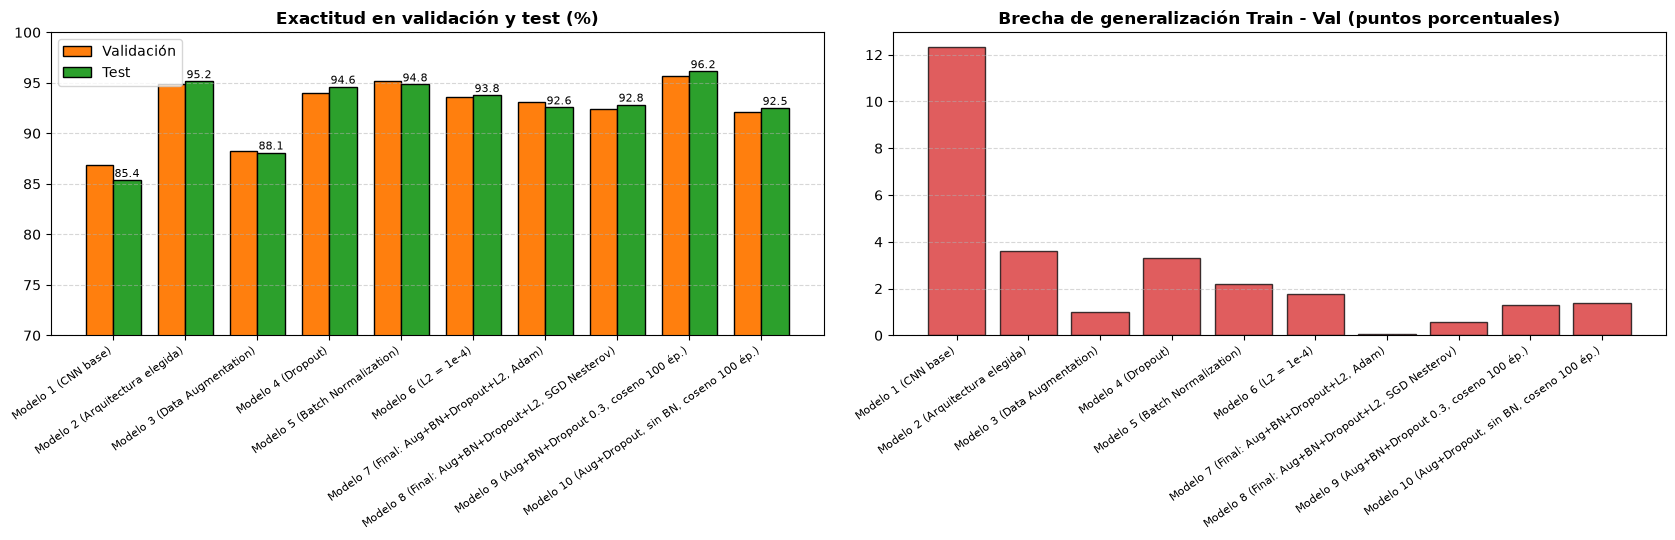

In [20]:
df_results = pd.DataFrame(results_registry).T
print("=" * 100)
print("TABLA RESUMEN - CNN PERSONALIZADAS EN EUROSAT")
print("=" * 100)
display(df_results)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 5.5))
x = np.arange(len(df_results))
w = 0.38
ax1.bar(x - w/2, df_results["Val Acc (%)"], w, label="Validación", color="#ff7f0e", edgecolor="black")
b = ax1.bar(x + w/2, df_results["Test Acc (%)"], w, label="Test", color="#2ca02c", edgecolor="black")
for bar in b:
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, f"{bar.get_height():.1f}", ha="center", fontsize=8)
ax1.set_ylim(70, 100)
ax1.set_xticks(x); ax1.set_xticklabels(df_results.index, rotation=35, ha="right", fontsize=8)
ax1.set_title("Exactitud en validación y test (%)", fontweight="bold"); ax1.legend(); ax1.grid(axis="y", linestyle="--", alpha=0.5)

ax2.bar(x, df_results["Brecha Train-Val (pp)"], color="#d62728", alpha=0.75, edgecolor="black")
ax2.set_xticks(x); ax2.set_xticklabels(df_results.index, rotation=35, ha="right", fontsize=8)
ax2.set_title("Brecha de generalización Train - Val (puntos porcentuales)", fontweight="bold")
ax2.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### 9.2. Comparación con la P1 (redes densas)
Los números de la P1 están copiados de la tabla final de su cuaderno (`P1_EuroSAT_NN.ipynb`), que usa **el mismo conjunto de test**.

Mejor CNN personalizada (por validación): Modelo 9 (Aug+BN+Dropout 0.3, coseno 100 ép.)


,Test Acc (%),Parámetros
Mejor MLP de la P1 (Modelo 4),65.09,6457482.0
CNN base (Modelo 1),85.38,1143242.0
"Mejor CNN: Modelo 9 (Aug+BN+Dropout 0.3, coseno 100 ép.)",96.15,306154.0


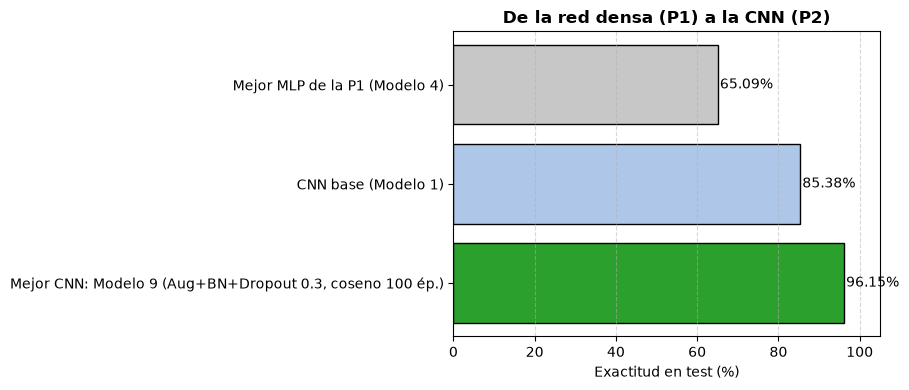

In [21]:
P1_RESULTS = {  # exactitud en test de los modelos de la P1 (tabla final de P1_EuroSAT_NN.ipynb)
    "P1 - Modelo 1 (MLP base)": 62.10,
    "P1 - Modelo 2 (L2)": 59.48,
    "P1 - Modelo 3 (Dropout 0.3)": 31.46,
    "P1 - Modelo 4 (Early Stopping)": 65.09,
    "P1 - Modelo 5 (BatchNorm)": 33.41,
    "P1 - Modelo 6 (Combinado)": 56.37,
}
P1_PARAMS = 6_457_482  # parámetros del MLP de la P1

best_cnn_name = df_results["Val Acc (%)"].astype(float).idxmax()  # el mejor se elige por VALIDACIÓN
best_cnn = models_registry[best_cnn_name]
print(f"Mejor CNN personalizada (por validación): {best_cnn_name}")

comparison = pd.DataFrame({
    "Test Acc (%)": [max(P1_RESULTS.values()), df_results.loc["Modelo 1 (CNN base)", "Test Acc (%)"],
                     df_results.loc[best_cnn_name, "Test Acc (%)"]],
    "Parámetros": [P1_PARAMS, df_results.loc["Modelo 1 (CNN base)", "Parámetros"],
                   df_results.loc[best_cnn_name, "Parámetros"]],
}, index=["Mejor MLP de la P1 (Modelo 4)", "CNN base (Modelo 1)", f"Mejor CNN: {best_cnn_name}"])
display(comparison)

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(comparison.index, comparison["Test Acc (%)"], color=["#c7c7c7", "#aec7e8", "#2ca02c"], edgecolor="black")
for bar in bars:
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2, f"{bar.get_width():.2f}%", va="center")
ax.set_xlim(0, 105); ax.set_xlabel("Exactitud en test (%)")
ax.set_title("De la red densa (P1) a la CNN (P2)", fontweight="bold")
ax.invert_yaxis(); ax.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### 9.3. Matriz de confusión y reporte por clase del mejor modelo

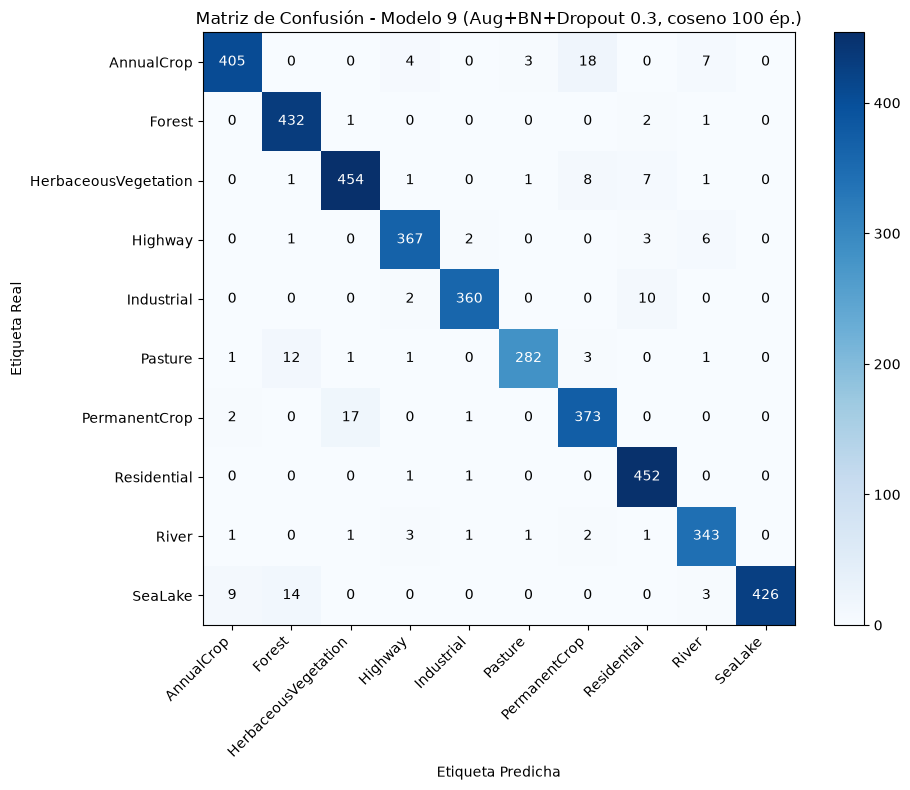

                      precision    recall  f1-score   support

          AnnualCrop      0.969     0.927     0.947       437
              Forest      0.939     0.991     0.964       436
HerbaceousVegetation      0.958     0.960     0.959       473
             Highway      0.968     0.968     0.968       379
          Industrial      0.986     0.968     0.977       372
             Pasture      0.983     0.937     0.959       301
       PermanentCrop      0.923     0.949     0.936       393
         Residential      0.952     0.996     0.973       454
               River      0.948     0.972     0.959       353
             SeaLake      1.000     0.942     0.970       452

            accuracy                          0.961      4050
           macro avg      0.963     0.961     0.961      4050
        weighted avg      0.962     0.961     0.961      4050



In [22]:
y_true_all, y_pred_all, x_all = [], [], []
for x_batch, y_batch in test_ds:
    preds = best_cnn.predict(x_batch, verbose=0)
    y_true_all.extend(np.argmax(y_batch.numpy(), axis=1))
    y_pred_all.extend(np.argmax(preds, axis=1))
    x_all.append(x_batch.numpy())
y_true_all, y_pred_all, x_all = np.array(y_true_all), np.array(y_pred_all), np.concatenate(x_all)

cm = confusion_matrix(y_true_all, y_pred_all)
plt.figure(figsize=(10, 8))
plt.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
plt.title(f"Matriz de Confusión - {best_cnn_name}", fontsize=12)
plt.colorbar()
ticks = np.arange(num_classes)
plt.xticks(ticks, class_names, rotation=45, ha="right"); plt.yticks(ticks, class_names)
thresh = cm.max() / 2.
for i in range(num_classes):
    for j in range(num_classes):
        plt.text(j, i, format(cm[i, j], "d"), ha="center", va="center", color="white" if cm[i, j] > thresh else "black")
plt.ylabel("Etiqueta Real"); plt.xlabel("Etiqueta Predicha")
plt.tight_layout()
plt.show()

report = classification_report(y_true_all, y_pred_all, target_names=class_names, output_dict=True)
print(classification_report(y_true_all, y_pred_all, target_names=class_names, digits=3))

### 9.4. F1 por clase: P1 frente a P2
El F1 de la P1 está copiado del `classification_report` de su mejor modelo. Así se ve **qué clases** mejoran más al pasar de una red densa a una convolucional.

,F1 P1 (MLP),F1 P2 (CNN),Mejora
Highway,0.30,0.968,0.668
PermanentCrop,0.52,0.936,0.416
River,0.58,0.959,0.379
HerbaceousVegetation,0.58,0.959,0.379
AnnualCrop,0.58,0.947,0.367
Residential,0.63,0.973,0.343
Pasture,0.71,0.959,0.249
Industrial,0.82,0.977,0.157
SeaLake,0.82,0.970,0.150
Forest,0.85,0.964,0.114


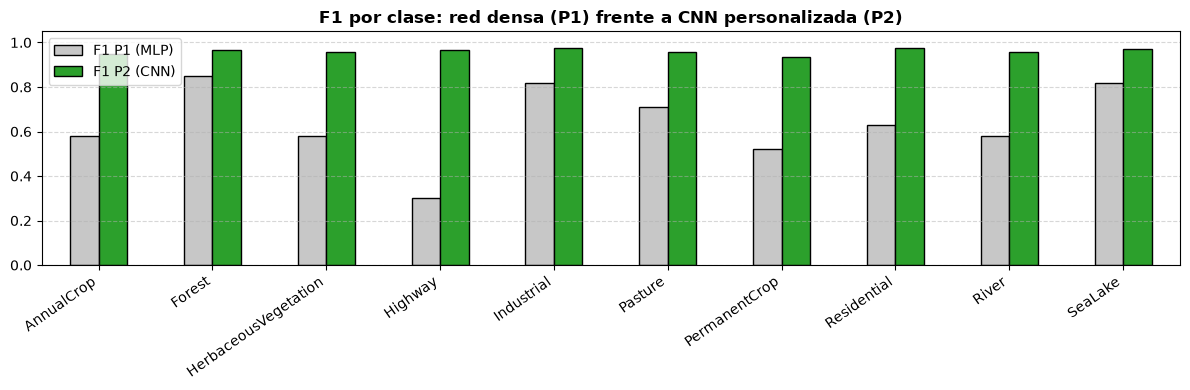

In [23]:
P1_F1 = {"AnnualCrop": 0.58, "Forest": 0.85, "HerbaceousVegetation": 0.58, "Highway": 0.30, "Industrial": 0.82,
         "Pasture": 0.71, "PermanentCrop": 0.52, "Residential": 0.63, "River": 0.58, "SeaLake": 0.82}
f1_cmp = pd.DataFrame({"F1 P1 (MLP)": P1_F1,
                       "F1 P2 (CNN)": {c: round(report[c]["f1-score"], 3) for c in class_names}})
f1_cmp["Mejora"] = (f1_cmp["F1 P2 (CNN)"] - f1_cmp["F1 P1 (MLP)"]).round(3)
display(f1_cmp.sort_values("Mejora", ascending=False))

f1_cmp[["F1 P1 (MLP)", "F1 P2 (CNN)"]].plot(kind="bar", figsize=(12, 4), color=["#c7c7c7", "#2ca02c"], edgecolor="black")
plt.title("F1 por clase: red densa (P1) frente a CNN personalizada (P2)", fontweight="bold")
plt.ylim(0, 1.05); plt.xticks(rotation=35, ha="right"); plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### 9.5. Ejemplos mal clasificados

Imágenes de test mal clasificadas: 156 de 4050


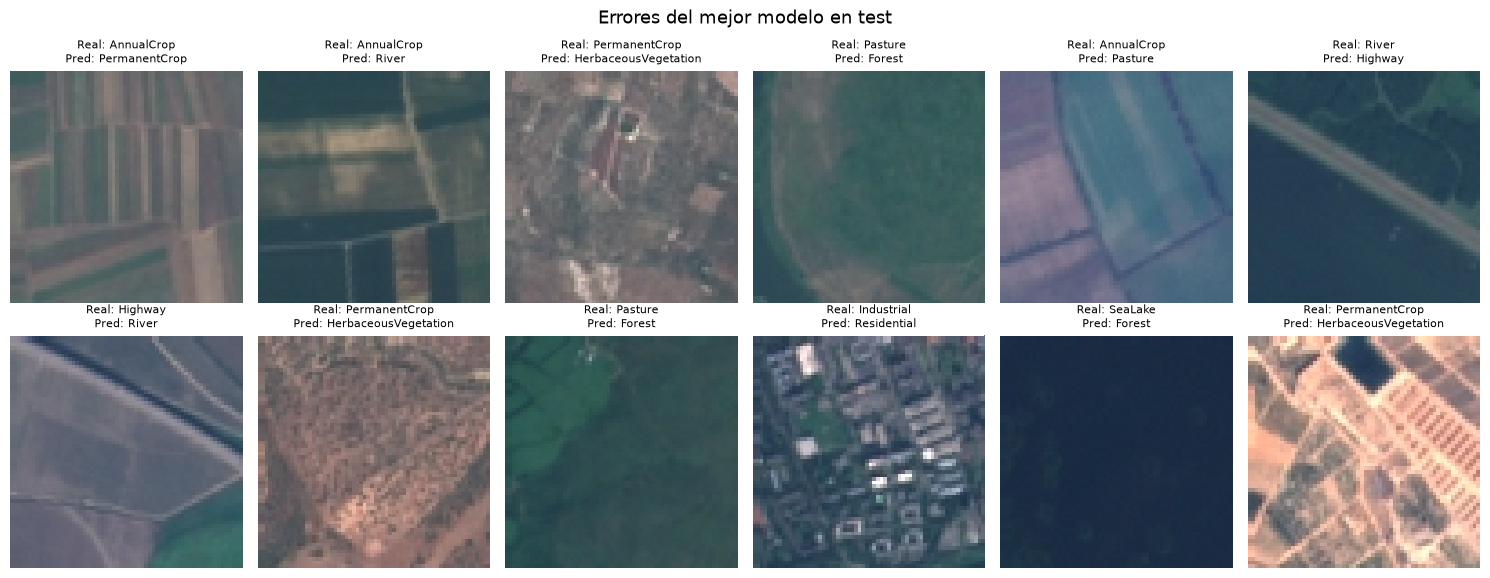

In [24]:
wrong = np.where(y_true_all != y_pred_all)[0]
print(f"Imágenes de test mal clasificadas: {len(wrong)} de {len(y_true_all)}")
rng = np.random.default_rng(SEED)
show = rng.choice(wrong, size=min(12, len(wrong)), replace=False)
plt.figure(figsize=(15, 6))
for k, idx in enumerate(show):
    plt.subplot(2, 6, k + 1)
    plt.imshow(x_all[idx])
    plt.title(f"Real: {class_names[y_true_all[idx]]}\nPred: {class_names[y_pred_all[idx]]}", fontsize=8)
    plt.axis("off")
plt.suptitle("Errores del mejor modelo en test", fontsize=13)
plt.tight_layout()
plt.show()

### 9.6. Qué "ve" la primera capa convolucional
Mostramos los 16 primeros mapas de activación de la primera convolución para una imagen de cada tipo. Cada mapa es la respuesta de un filtro en cada posición de la imagen: así se ve que la red trabaja sobre la estructura 2D (bordes, texturas, zonas de agua) que el aplanado de la P1 destruía.

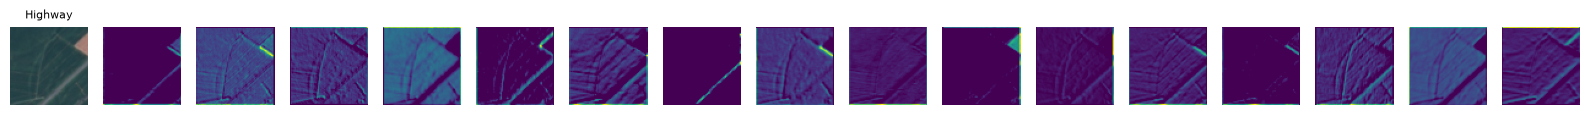

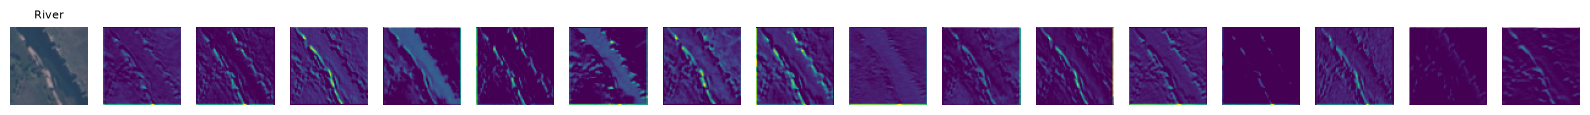

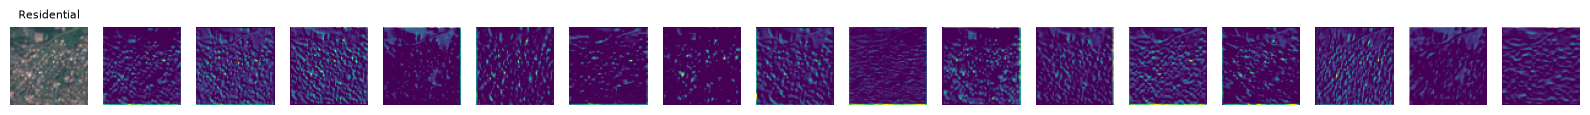

In [25]:
first_conv = [l for l in best_cnn.layers if isinstance(l, layers.Conv2D)][0]
activation_after = best_cnn.get_layer(first_conv.name.replace("conv", "relu"))
feature_model = keras.Model(best_cnn.inputs, activation_after.output)

for cls in ["Highway", "River", "Residential"]:
    idx = np.where(y_true_all == class_names.index(cls))[0][0]
    fmap = feature_model.predict(x_all[idx:idx + 1], verbose=0)[0]
    plt.figure(figsize=(16, 2.4))
    plt.subplot(1, 17, 1); plt.imshow(x_all[idx]); plt.title(cls, fontsize=8); plt.axis("off")
    for ch in range(16):
        plt.subplot(1, 17, ch + 2); plt.imshow(fmap[:, :, ch], cmap="viridis"); plt.axis("off")
    plt.tight_layout()
    plt.show()

### 9.7. Guardado de resultados para el cuaderno 2

In [26]:
summary = {
    "results": df_results.reset_index(names="Modelo").to_dict(orient="records"),
    "arch_search": df_arch.reset_index(names="Arquitectura").to_dict(orient="records"),
    "best_model": best_cnn_name,
    "best_arch": best_arch_name,
    "per_class_f1": {c: report[c]["f1-score"] for c in class_names},
}
with open(os.path.join(RESULTS_DIR, "p2_1_cnn_personalizada.json"), "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2, default=float)
print("Resultados guardados en", os.path.join(RESULTS_DIR, "p2_1_cnn_personalizada.json"))

Resultados guardados en resultados/p2_1_cnn_personalizada.json


<a id="sec10"></a>
## 10. Conclusiones
### 1. De la red densa (P1) a la CNN (P2)
* El mejor modelo pasa del **65,09% (MLP de la P1) al 96,15% en test (Modelo 9)**, sobre el mismo conjunto de test, con **306.154 parámetros frente a 6.457.482: 21 veces menos**. Los errores bajan de ~1.414 a 156 imágenes de 4.050.
* **Todas las clases superan un F1 de 0,93.** La mayor mejora es la de **Highway (0,30 → 0,97)**: una autopista es una forma alargada con bordes rectos. En los mapas de activación de la sección 9.6 hay filtros de la primera capa que responden solo al borde diagonal de la carretera. Esa forma solo se puede detectar si se conserva qué píxeles son vecinos, y es lo que el aplanado de la P1 destruía.
* Ya con la CNN base sin regularizar (85,38%) se superan en 20 puntos los resultados de la P1: la mejora se debe sobre todo a la **arquitectura convolucional**, no a los trucos de entrenamiento.

### 2. Arquitectura
* Lo que más mejora es: **profundidad** (3-4 bloques), **kernels 3x3** (mejor que 5x5) y, sobre todo, **sustituir `Flatten` por `GlobalAveragePooling`**, que quita el 92% de los parámetros y la mayor parte del sobreajuste. Ensanchar la red (más filtros) no ayuda.

### 3. Regularización (cada medida por separado, 40 épocas)
| Medida | Efecto en la brecha | Efecto en la exactitud | Observación |
|---|---|---|---|
| Ninguna (GAP) | 3,6 pp | 94,9% val | Sobreajuste leve |
| Aumento de datos | **1,0 pp** | 88,2% (infrajuste) | El más eficaz contra el sobreajuste; necesita muchas épocas |
| Dropout | 3,3 pp | 94,0% | Suave, sin infrajuste (a diferencia de la P1) |
| Batch Normalization | 2,2 pp | 95,2% | Converge muy rápido; validación muy inestable con $\eta$ fija |
| $L_2$ | 1,75 pp | 93,6% | Más estable, algo menos exacto |

### 4. Combinación y optimización: la lección principal
* **Los regularizadores no se suman.** Juntar los cuatro (Modelos 7 y 8) provocó infrajuste y peores resultados que no usar ninguno.
* **Con BN, la tasa de aprendizaje importa más que el optimizador.** Adam y SGD llegaron al mismo límite (Modelos 7 y 8). Lo que resolvió el problema fue **sustituir `EarlyStopping` y `ReduceLROnPlateau`, que reaccionan a una validación ruidosa, por un programa fijo de calentamiento y decaimiento coseno** durante 100 épocas (Modelo 9). Al final del programa la tasa es casi 0, la validación se estabiliza y BN da su mejor resultado. Sin BN, la misma receta pierde 3,6 puntos (Modelo 10).
* Es el mismo tipo de proceso que en la P1 (de V1 a V2 del Modelo 6): la primera combinación falla, se diagnostica con las curvas y se corrige.

### 5. Errores que quedan (matriz de confusión del Modelo 9)
* **Entre clases agrícolas:** AnnualCrop → PermanentCrop (18), PermanentCrop → HerbaceousVegetation (17). Son parcelas con texturas y colores muy parecidos a 10 m por píxel.
* **Agua muy oscura:** SeaLake → Forest (14) y SeaLake → AnnualCrop (9). En la sección 9.5 se ven imágenes de mar casi negras y sin textura, que se parecen más a un bosque denso en sombra que a un lago.
* **Pasture → Forest (12)** e **Industrial → Residential (10)**: también hay casos en los que distinguir las clases es difícil a esta resolución.

### 6. Metodología
* Todas las elecciones se hicieron con el **conjunto de validación**. El test solo se ha usado para informar. Entre dos ejecuciones completas de este cuaderno, un mismo modelo varió hasta ~1,4 puntos en test (Modelo 1: 86,79% y 85,38%) por el no determinismo de la GPU, así que **las diferencias de menos de ~1 punto entre modelos no son concluyentes**. Las de la tabla final (P1 → CNN base → Modelo 9) sí lo son.
* En el cuaderno 2 se comparan estos resultados con los de las redes preentrenadas.